# Map plots of equation terms between historical and future simulations
This Notebook permits to plot the extreme exceedance in the future and historical period of regional simulations and the difference between both. It also shows the contribution of each three terms of the equation to highlight which one is driving the change of extreme exceedance.

In [1]:
import xarray as xr
import pickle
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy
from matplotlib.ticker import FuncFormatter
import numpy as np
from scipy.ndimage import gaussian_filter
import matplotlib.colors as mcolors
import cmcrameri.cm as cmc
import string

# Loading Data

In [2]:
# Tropical cyclone filter of the cyclone-related inputs (see ETC_tools.py): None (all
# cyclones, as in the submitted version), 'phase' (only the extratropical time steps)
# or 'storm' (no cyclone with a tropical phase). The percentiles do not depend on it.
tc_filter = 'phase'
tc_tag = {None: '', 'phase': '_noTC', 'storm': '_noTCstorm'}[tc_filter]

simulations = ['UBD', 'UBE', 'UBF', 'UBG', 'UBH', 'UBI']
sim_hist_fut = {'UBD': 'UBG', 'UBE': 'UBH', 'UBF': 'UBI'}

ds_dens = {}
percentile = {}

for sim in simulations:

    if sim in sim_hist_fut:
        
        start_year, end_year = 1980, 2014
            
        for var in ['pr', 'ws']:
            if var == 'pr':
                percentile_path = f'/home/vdemeyer/projects/rrg-gachon/vdemeyer/{sim}/PR_Percentile/pr_{sim.lower()}_percentile_{start_year}-{end_year}.nc'
            else:
                percentile_path = f'/home/vdemeyer/projects/rrg-gachon/vdemeyer/{sim}/WIND_Percentile/surf_wind_{sim.lower()}_percentile_{start_year}-{end_year}.nc'
    
            percentile[(sim, var)] = xr.open_dataset(percentile_path)

    file = f"/project/rrg-gachon/vdemeyer/{sim}/STORM_RELATED/DENSITY/density_ETCs_center_{sim.lower()}_all_seasons{tc_tag}.nc"
    ds = xr.open_dataset(file)
    ds_dens[sim] = ds

In [3]:
file_path = f'/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/CONTRIB/contribution_ETCs_1000hPa{tc_tag}.pkl'

with open(file_path, 'rb') as file:
    data = pickle.load(file)

# Map plots

## Function to plot the maps

In [4]:
for_pole = xr.open_mfdataset('/home/vdemeyer/projects/rrg-gachon/vdemeyer/UBB/PR/pr_ubb_199102_se.nc')
pole_lon = for_pole.rotated_pole.attrs['grid_north_pole_longitude']
pole_lat = for_pole.rotated_pole.attrs['grid_north_pole_latitude']
polecrs = ccrs.RotatedPole(pole_longitude=pole_lon, pole_latitude=pole_lat)

def clean_float(x, pos):
    """Formateur pour retirer les notations scientifiques pour les petits nombres."""
    if abs(x) < 1e-8: # seuil de tolérance (adjustable)
        x = 0
    return '%g' % x
    
sim_label = {
    'ERA5': r'ERA5',
    'UBB': r'CRCM6$_{\mathbf{ERA5}}$',
    'UBD': r'CRCM6$_{\mathbf{EC\text{-}Earth3\text{-}Veg}}$',
    'UBG': r'CRCM6$_{\mathbf{EC\text{-}Earth3\text{-}Veg}}$',
    'UBE': r'CRCM6$_{\mathbf{MPI\text{-}ESM1\text{-}2\text{-}HR}}$',
    'UBH': r'CRCM6$_{\mathbf{MPI\text{-}ESM1\text{-}2\text{-}HR}}$',
    'UBF': r'CRCM6$_{\mathbf{MIROC6}}$',
    'UBI': r'CRCM6$_{\mathbf{MIROC6}}$'
}

sim_label_nobold = {
    'ERA5': r'ERA5',
    'UBB': r'CRCM6$_{\mathrm{ERA5}}$',
    'UBD': r'CRCM6$_{\mathrm{EC\text{-}Earth3\text{-}Veg}}$',
    'UBG': r'CRCM6$_{\mathrm{EC\text{-}Earth3\text{-}Veg}}$',
    'UBE': r'CRCM6$_{\mathrm{MPI\text{-}ESM1\text{-}2\text{-}HR}}$',
    'UBH': r'CRCM6$_{\mathrm{MPI\text{-}ESM1\text{-}2\text{-}HR}}$',
    'UBF': r'CRCM6$_{\mathrm{MIROC6}}$',
    'UBI': r'CRCM6$_{\mathrm{MIROC6}}$'
}

def get_colormap(colormap_name, style=None, rework=True):
    """
    Récupère une colormap, avec une modification spéciale pour 'Spectral_r'.
    """
    # Si l'entrée est déjà une colormap (comme cmocean.cm.curl)
    if hasattr(colormap_name, '__call__'):
        return colormap_name

    # Cas spécial pour 'Spectral_r' avec style différent de 'pcolormesh'
    if colormap_name == 'Spectral_r' and style != 'pcolormesh' and rework == True:
        spectral = plt.colormaps['Spectral_r']
        colors = spectral(np.linspace(0, 1, 256))
        colors[128:145] = colors[128:145] * 0.95  # Reduce brightness at the center
        return mcolors.LinearSegmentedColormap.from_list('ModifiedSpectral', colors)

    # Sinon, essaie de la récupérer parmi les colormaps enregistrées (matplotlib ou ajoutées comme cmocean)
    try:
        return plt.get_cmap(colormap_name)
    except ValueError:
        raise ValueError(f"Colormap '{colormap_name}' not found.")

def _setup_plot_axes(positions, figsize, plotcrs=ccrs.LambertConformal(central_latitude=45, central_longitude=-95)):
    """Initialise la figure et les axes Cartopy."""
    fig = plt.figure(figsize=figsize)
    axes = [fig.add_axes(pos, projection=plotcrs) for pos in positions]
    crs = polecrs
    return fig, axes, crs       

def _draw_map_features(ax):
    """Ajoute les entités géographiques (frontières, lacs, grille) à un axe."""
    # ax.set_extent([-128, -57, 75, 14], crs=ccrs.PlateCarree())
    ax.set_extent([-128, -56, 81, 12], crs=ccrs.PlateCarree())
    
    borders = cartopy.feature.NaturalEarthFeature(category='cultural', name='admin_0_boundary_lines_land', scale='50m', facecolor='none')
    states_provinces = cartopy.feature.NaturalEarthFeature(category='cultural', name='admin_1_states_provinces', scale='50m', facecolor='none')
    lakes_color = cartopy.feature.NaturalEarthFeature(category='physical', name='lakes', scale='50m', facecolor='#7FB4D8', edgecolor='black')
    lakes_edge = cartopy.feature.NaturalEarthFeature(category='physical', name='lakes', scale='50m', facecolor='none', edgecolor='black')
    img = plt.imread('/home/vdemeyer/TOOLS/NE1_50M_SR_W.tif')
    
    ax.imshow(img, origin='upper', extent=(-180, 180, -90, 90), transform=ccrs.PlateCarree())
    ax.add_feature(borders, linewidth=0.5, edgecolor='black', zorder=2)
    ax.add_feature(states_provinces, edgecolor='black', linewidth=0.3)
    ax.add_feature(lakes_color, zorder=1, linewidth=0.3)
    ax.add_feature(lakes_edge, zorder=2, linewidth=0.3)
    ax.coastlines(resolution='10m', linewidth=0.4, color='black')
    ax.gridlines(linewidth=0.5, linestyle='--', color='k', alpha=0.25, xlocs=range(-180,180,10), ylocs=range(-90,90,10))

def _calculate_contourf_levels(vmin, vmax, step, ting):
    """Calcule les niveaux pour contourf, en gérant le cas de symétrie et 'ting'."""
    if step is None:
        raise ValueError("Step cannot be None for contourf style.")
        
    if vmin < 0:
        absmax = max(abs(vmin), abs(vmax))
        # Arrondir absmax au multiple supérieur de step
        nice_max = np.ceil(absmax / step) * step
        vmin = -nice_max
        vmax = +nice_max
        
    if ting:
        # Les niveaux 0.5, 2, 5 sont inclus avant l'échelle régulière
        levels = [0.5, 2, 5] + list(np.arange(10, vmax + step, step))
    else:
        levels = np.arange(vmin, vmax + step, step)
    
    return vmin, vmax, levels

def _plot_data_on_ax(ax, data_xr, crs, style, colormap, vmin, vmax, step, extend_opt, ting=False, 
                     data_hist=None, sigma=None, contour_color='k', contour_levels=None, fmt=None):
    """Effectue le plot (pcolormesh ou contourf) et ajoute les contours."""
    var_lon = 'rlon'
    var_lat = 'rlat'
    
    cmap = get_colormap(colormap, style, rework=(colormap=='Spectral_r' and style != 'pcolormesh')) 
    
    sc = None
    levels = None
    
    if style == 'pcolormesh':
        sc = ax.pcolormesh(
            data_xr[var_lon], data_xr[var_lat], data_xr,
            transform=crs, cmap=cmap, vmin=vmin, vmax=vmax, shading='auto'
        )
    else: # contourf
        vmin, vmax, levels = _calculate_contourf_levels(vmin, vmax, step, ting)
        
        sc = ax.contourf(
            data_xr[var_lon], data_xr[var_lat], data_xr,
            transform=crs, levels=levels + 1e-9, cmap=cmap, vmin=vmin, vmax=vmax, extend=extend_opt
        )
            
    if data_hist is not None:
        to_plot = gaussian_filter(data_hist, sigma=sigma) if sigma is not None else data_hist
    
        contour_kwargs = dict(
            levels=contour_levels,
            linewidths=1.6,
            alpha=1.,
            transform=crs,
        )
    
        if isinstance(contour_color, mcolors.Colormap):
            contour_kwargs["cmap"] = contour_color
        else:
            contour_kwargs["colors"] = contour_color
    
        contours = ax.contour(
            data_hist[var_lon],
            data_hist[var_lat],
            to_plot,
            **contour_kwargs
        )
    
        ax.clabel(contours, inline=True, fontsize=10, fmt=fmt, inline_spacing=3)
        
    return sc, levels

def _add_cbar(fig, sc, cbar_ax, label, style, levels=None, cb_int=False, extend_opt='both'):
    """Ajoute une barre de couleur standard ou pour contourf avec formatage optionnel."""
    if sc is None:
        return
        
    if style == 'pcolormesh':
        cbar = fig.colorbar(sc, cax=cbar_ax, orientation="horizontal", pad=0.02, extend=extend_opt)
    else:
        cbar = fig.colorbar(sc, cax=cbar_ax, orientation="horizontal", pad=0.02)
        if cb_int and levels is not None:
            int_levels = [l if l == 0.5 else int(l) for l in levels]
            cbar.set_ticklabels(int_levels)
        elif levels is not None:
            cbar.ax.xaxis.set_major_formatter(FuncFormatter(clean_float))
            
    cbar.set_label(label, fontsize=18)
    cbar.ax.tick_params(labelsize=18)
    return cbar

def plot_map(data_input, simulations, colormap, vmin, vmax, label, style='pcolormesh', data_hist=None, contour_levels=None, fmt=None, sigma=None, step=None, ting=False, cb_int=False, **kwargs):
    
    positions = [
        [0.05, 0.10, 0.29, 0.29],  # Rangée du haut, Colonne 1
        [0.35, 0.10, 0.29, 0.29],  # Rangée du haut, Colonne 2
        [0.65, 0.10, 0.29, 0.29],  # Rangée du haut, Colonne 3
    ]

    fig, axes, crs = _setup_plot_axes(positions, figsize=(16,16))

    if colormap == 'coolwarm':
        extend_opt = 'both'
    else:
        if vmax == 100:
            extend_opt = None
        else:
            extend_opt = 'max'
        
    for i, (ax, sim) in enumerate(zip(axes, simulations)):

        _draw_map_features(ax)

        data_hist_this = data_hist.get(sim) if isinstance(data_hist, dict) else data_hist
        clev_this = contour_levels.get(sim) if isinstance(contour_levels, dict) else contour_levels
        fmt_this = fmt.get(sim) if isinstance(fmt, dict) else fmt
            
        sc, levels = _plot_data_on_ax(
            ax, data_input[sim], crs, style, colormap, vmin, vmax, step, extend_opt, ting,
            data_hist=data_hist_this, sigma=sigma, contour_levels=clev_this, fmt=fmt_this
        )
  
        ax.text(0.02, 0.98, sim_label[sim], transform=ax.transAxes, fontsize=17, fontweight='bold',
                ha='left', va='top', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2'))
        
        letter = f"$\\mathbf{{{chr(97+i)})}}$"
        ax.text(0, 1.02, letter, transform=ax.transAxes, fontsize=21, ha='left', va='bottom')
        
    left_min = min(pos[0] for pos in positions)
    left_max = max(pos[0] + pos[2] for pos in positions)
    cbar_ax = fig.add_axes([left_min, 0.065, left_max - left_min, 0.02])
    
    _add_cbar(fig, sc, cbar_ax, label, style, levels, cb_int, extend_opt=extend_opt)

def plot_map_terms(input_arr, simulations, vmin, vmax, label, extend_opt='both', colormap="coolwarm", style='pcolormesh', contour_color='k', data_hist=None, contour_levels=None, fmt=None, sigma=None, step=None, ting=False, cb_int=False, **kwargs):

    nrows = 3
    ncols = 3
    
    positions = [
        [0.0, 0.71, 0.3, 0.3],
        [0.31, 0.71, 0.3, 0.3],
        [0.62, 0.71, 0.3, 0.3],
        
        [0.0, 0.38, 0.3, 0.3],
        [0.31, 0.38, 0.3, 0.3],
        [0.62, 0.38, 0.3, 0.3],
    
        [0.0, 0.05, 0.3, 0.3],
        [0.31, 0.05, 0.3, 0.3],
        [0.62, 0.05, 0.3, 0.3],
    ]

    ax_width, ax_height = positions[0][2], positions[0][3]
    left_margin, bottom_margin = min(p[0] for p in positions), min(p[1] for p in positions)
    top_margin, right_margin = 1 - max(p[1] + p[3] for p in positions), 1 - max(p[0] + p[2] for p in positions)

    fig, axes, crs = _setup_plot_axes(positions, figsize=(16,16))

    # Détecter le type de variable
    first_da = list(input_arr[0].values())[0]
    var_name = str(first_da.coords["variable"].item()) if "variable" in first_da.coords else None
    var_label = (
        "WS" if "ws" in var_name.lower()
        else "PR" if "pr" in var_name.lower()
        else (_ for _ in ()).throw(ValueError(f"Variable '{var_name}' non reconnue"))
    )
        
    term_labels = [
        r"$T_{ETC}^{hist}(x) \cdot \Delta \overline{" + var_label + "_{ETC}}(x)$",
        r"$- T_{ETC}^{hist}(x) \cdot \Delta {" + var_label + "}_{th}(x)$",
        r"$\overline{EE_{" + var_label + "}^{fut}}(x) \cdot \Delta T_{ETC}(x)$"
    ]
        
    sim_label = [
        r'CRCM6$_{\mathbf{EC\text{-}Earth3\text{-}Veg}}$',
        r'CRCM6$_{\mathbf{MPI\text{-}ESM1\text{-}2\text{-}HR}}$',
        r'CRCM6$_{\mathbf{MIROC6}}$'
    ]
    
    # Ajout titres de colonnes (termes)
    for col in range(ncols):
        # Centrer au-dessus de la colonne
        left = positions[col][0] + ax_width/2
        top = 1 - top_margin + 0.01  # juste au-dessus du top margin
        fig.text(left, top, term_labels[col], ha='center', va='bottom', fontsize=20, fontweight='bold')
    
    # Ajout titres de lignes (modèles), vertical à gauche
    for row in range(nrows):
        # Prendre la première colonne de chaque ligne
        left = left_margin - 0.01  # juste à gauche du plot
        bottom = positions[row*ncols][1] + ax_height/2
        fig.text(left, bottom, sim_label[row], ha='right', va='center', fontsize=20, fontweight='bold', rotation=90)

    for row_idx, sim in enumerate(simulations):
        for col_idx, input_dict in enumerate(input_arr):
            i = row_idx * 3 + col_idx
            ax = axes[i]
        
            _draw_map_features(ax)
            
            data_hist_this = data_hist.get(sim) if isinstance(data_hist, dict) else data_hist
            clev_this = contour_levels.get(sim) if isinstance(contour_levels, dict) else contour_levels
            fmt_this = fmt.get(sim) if isinstance(fmt, dict) else fmt

            sc, levels = _plot_data_on_ax(
                ax, input_dict[sim], crs, style, colormap, vmin, vmax, step, extend_opt, ting,
                data_hist=data_hist_this, sigma=sigma, contour_color=contour_color, contour_levels=clev_this, fmt=fmt_this
            )
    
            # ax.text(0.02, 0.98, sim_label[sim], transform=ax.transAxes, fontsize=17, fontweight='bold',
            #         ha='left', va='top', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2'))
            
            letter = f"$\\mathbf{{{chr(97+i)})}}$"
            ax.text(0, 1.01, letter, transform=ax.transAxes, fontsize=20, ha='left', va='bottom')
        
    left_min = min(pos[0] for pos in positions)
    left_max = max(pos[0] + pos[2] for pos in positions)
    cbar_ax = fig.add_axes([left_min, 0.02, left_max - left_min, 0.02])
    
    _add_cbar(fig, sc, cbar_ax, label, style, levels, cb_int, extend_opt=extend_opt)

def plot_map_terms_2cbar(
    input_arr,
    simulations,
    col_cfg,
    style="contourf",
    contour_color='k',
    data_hist=None,
    contour_levels=None,
    sigma=None,
    fmt=None,
    ting=False,
    cb_int=False,
):
    
    nrows = 3
    ncols = 2
    
    positions = [
        [0.0,  0.57, 0.23, 0.23],
        [0.24, 0.57, 0.23, 0.23],
    
        [0.0,  0.31, 0.23, 0.23],
        [0.24, 0.31, 0.23, 0.23],
    
        [0.0,  0.05, 0.23, 0.23],
        [0.24, 0.05, 0.23, 0.23],
    ]

    ax_width, ax_height = positions[0][2], positions[0][3]
    left_margin, bottom_margin = min(p[0] for p in positions), min(p[1] for p in positions)
    top_margin, right_margin = 1 - max(p[1] + p[3] for p in positions), 1 - max(p[0] + p[2] for p in positions)
    wspace = positions[1][0] - (positions[0][0] + positions[0][2])

    # Détecter le type de variable
    first_da = list(input_arr[0].values())[0]
    var_name = str(first_da.coords["variable"].item()) if "variable" in first_da.coords else None
    var_label = (
        "WS" if "ws" in var_name.lower()
        else "PR" if "pr" in var_name.lower()
        else (_ for _ in ()).throw(ValueError(f"Variable '{var_name}' non reconnue"))
    )

    term_labels = [
        rf'$\Delta \overline{{{{{var_label}}}_{{ETC}}}}(x)$',
        rf'$\Delta T_{{ETC}}(x)$'
    ]
    
    sim_label = [
        r'CRCM6$_{\mathbf{EC\text{-}Earth3\text{-}Veg}}$',
        r'CRCM6$_{\mathbf{MPI\text{-}ESM1\text{-}2\text{-}HR}}$',
        r'CRCM6$_{\mathbf{MIROC6}}$'
    ]
    
    fig, axes, crs = _setup_plot_axes(positions, figsize=(16,16))

    sc_by_col = [None] * ncols
    levels_by_col = [None] * ncols
    
    # Ajout titres de colonnes (termes)
    for col in range(ncols):
        # Centrer au-dessus de la colonne
        left = positions[col][0] + ax_width/2
        top = 1 - top_margin + 0.01  # juste au-dessus du top margin
        fig.text(left, top, term_labels[col], ha='center', va='bottom', fontsize=20, fontweight='bold')
    
    # Ajout titres de lignes (modèles), vertical à gauche
    for row in range(nrows):
        # Prendre la première colonne de chaque ligne
        left = left_margin - 0.01  # juste à gauche du plot
        bottom = positions[row*ncols][1] + ax_height/2
        fig.text(left, bottom, sim_label[row], ha='right', va='center', fontsize=20, fontweight='bold', rotation=90)
        
    for row_idx, sim in enumerate(simulations):
        for col_idx, dct in enumerate(input_arr):
            i = row_idx * ncols + col_idx
            ax = axes[i]
            cfg = col_cfg[col_idx]

            _draw_map_features(ax)

            # paramètres colonne
            vmin = cfg["vmin"]
            vmax = cfg["vmax"]
            step = cfg.get("step", None)
            label = cfg["label"]
            cmap = cfg.get("colormap", "coolwarm")
            extend_opt = cfg.get("extend_opt", "both")

            # contours (optionnels), par sim ou globaux
            data_hist_this = data_hist.get(sim) if isinstance(data_hist, dict) else data_hist
            clev_this = contour_levels.get(sim) if isinstance(contour_levels, dict) else contour_levels
            fmt_this = fmt.get(sim) if isinstance(fmt, dict) else fmt

            sc, levels = _plot_data_on_ax(
                ax=ax,
                data_xr=dct[sim],
                crs=crs,
                style=style,
                colormap=cmap,
                vmin=vmin,
                vmax=vmax,
                step=step,
                extend_opt=extend_opt,
                ting=ting,
                data_hist=data_hist_this,
                sigma=sigma,
                contour_levels=clev_this,
                contour_color=contour_color,
                fmt=fmt_this,
            )

            if sc_by_col[col_idx] is None:
                sc_by_col[col_idx] = sc
                levels_by_col[col_idx] = levels

            # ax.text(
            #     0.02, 0.98, sim_label[sim],
            #     transform=ax.transAxes, fontsize=21, fontweight='bold',
            #     ha='left', va='top',
            #     bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2')
            # )
            letter = f"$\\mathbf{{{chr(97+i)})}}$"
            ax.text(0, 1.02, letter, transform=ax.transAxes, fontsize=22, ha='left', va='bottom')

    # 3 colorbars (une sous chaque colonne)
    cbar_height = 0.02
    cbar_bottom = 0.02

    for col_idx in range(ncols):
        cfg = col_cfg[col_idx]
        cbar_left = left_margin + col_idx * (ax_width + wspace)
        cbar_ax = fig.add_axes([cbar_left, cbar_bottom, ax_width, cbar_height])

        _add_cbar(
            fig=fig,
            sc=sc_by_col[col_idx],
            cbar_ax=cbar_ax,
            label=cfg["label"],
            style=style,
            levels=levels_by_col[col_idx],
            cb_int=cb_int,
            extend_opt=cfg.get("extend_opt", "both"),
        )


def plot_map_four_per_three(
    input_arr,
    vmin,
    vmax,
    label,
    extend_opt='both',
    colormap="coolwarm",
    style='pcolormesh',
    contour_color='k',
    data_hist=None,
    contour_levels=None,
    fmt=None,
    sigma=None,
    step=None,
    ting=False,
    cb_int=False,
    **kwargs
):

    ncols = 3
    nrows = 4

    positions = [
        # Ligne 1
        [0.0, 0.83, 0.23, 0.23],
        [0.24, 0.83, 0.23, 0.23],
        [0.48, 0.83, 0.23, 0.23],
    
        # Ligne 2
        [0.0, 0.57, 0.23, 0.23],
        [0.24, 0.57, 0.23, 0.23],
        [0.48, 0.57, 0.23, 0.23],
    
        # Ligne 3
        [0.0, 0.31, 0.23, 0.23],
        [0.24, 0.31, 0.23, 0.23],
        [0.48, 0.31, 0.23, 0.23],
    
        # Ligne 4
        [0.0, 0.05, 0.23, 0.23],
        [0.24, 0.05, 0.23, 0.23],
        [0.48, 0.05, 0.23, 0.23],
    ]
    
    ax_width, ax_height = positions[0][2], positions[0][3]
    left_margin, bottom_margin = min(p[0] for p in positions), min(p[1] for p in positions)
    top_margin, right_margin = 1 - max(p[1] + p[3] for p in positions), 1 - max(p[0] + p[2] for p in positions)

    fig, axes, crs = _setup_plot_axes(positions, figsize=(16,16))

    # Détecter le type de variable
    first_da = list(input_arr[0].values())[0]
    var_name = str(first_da.coords["variable"].item()) if "variable" in first_da.coords else None
    var_label = (
        "WS" if "ws" in var_name.lower()
        else "PR" if "pr" in var_name.lower()
        else (_ for _ in ()).throw(ValueError(f"Variable '{var_name}' non reconnue"))
    )
        
    term_labels = [
        r"$\Delta EE_{" + var_label + ",cum|ETC}(x)$",
        r"$T_{ETC}^{hist}(x) \cdot \Delta \overline{" + var_label + "_{ETC}}(x)$",
        r"$\overline{EE_{" + var_label + "}^{fut}}(x) \cdot \Delta T_{ETC}(x)$"
    ]

    season_label = ['JJA', 'SON', 'DJF', 'MAM']

    # Ajout titres de colonnes (termes)
    for col in range(ncols):
        # Centrer au-dessus de la colonne
        left = positions[col][0] + ax_width/2
        top = 1 - top_margin + 0.01  # juste au-dessus du top margin
        fig.text(left, top, term_labels[col], ha='center', va='bottom', fontsize=20, fontweight='bold')

    # Ajout titres de lignes (modèles), vertical à gauche
    for row in range(nrows):
        # Prendre la première colonne de chaque ligne
        left = left_margin - 0.005  # juste à gauche du plot
        bottom = positions[row*ncols][1] + ax_height/2
        fig.text(left, bottom, season_label[row], ha='right', va='center', fontsize=20, rotation=90)
            
    for row_idx, season in enumerate(season_label):
        for col_idx, input_dict in enumerate(input_arr):
            i = row_idx * ncols + col_idx
            ax = axes[i]
    
            _draw_map_features(ax)

        
            if col_idx == 0:
                # Première colonne : term_total
                data_to_plot = input_arr[0][season]          # term_total
                data_hist_to_use = data_hist[0][season]     # term_total_hist
                contour_levels_to_use = contour_levels[0][season]  # contour_levels_term_total
            
            else:
                # Colonnes 1,2,3 → term1, # term2, term2
                data_to_plot = input_arr[col_idx][season]
            
                if len(data_hist) == 1:
                    # Pas de contours si un seul élément dans data_hist
                    data_hist_to_use = None
                    contour_levels_to_use = None
                else:
                    data_hist_to_use = data_hist[1][season]     # terms_total
                    contour_levels_to_use = contour_levels[1][season]  # contour_levels_terms
                
            sc, levels = _plot_data_on_ax(
                ax, data_to_plot, crs, style, colormap, vmin, vmax, step, extend_opt, ting,
                data_hist=data_hist_to_use, sigma=sigma, contour_color=contour_color, contour_levels=contour_levels_to_use, fmt=fmt
            )
        
            letter = f"$\\mathbf{{{chr(97+i)})}}$"
            ax.text(0, 1.01, letter, transform=ax.transAxes, fontsize=20, ha='left', va='bottom')

    left_min = min(pos[0] for pos in positions)
    left_max = max(pos[0] + pos[2] for pos in positions)
    cbar_ax = fig.add_axes([left_min, 0.01, left_max - left_min, 0.025])

    _add_cbar(fig, sc, cbar_ax, label, style, levels, cb_int, extend_opt=extend_opt)


def plot_map_four_per_three_season(data_input, simulations, colormap, vmin, vmax, label, style='pcolormesh', data_hist=None, contour_levels=None, fmt=None, sigma=None, step=None, ting=False, cb_int=False, **kwargs):

    ncols = 3
    nrows = 4
    
    positions = [
        # Ligne 1
        [0.0, 0.83, 0.23, 0.23],
        [0.24, 0.83, 0.23, 0.23],
        [0.48, 0.83, 0.23, 0.23],
    
        # Ligne 2
        [0.0, 0.57, 0.23, 0.23],
        [0.24, 0.57, 0.23, 0.23],
        [0.48, 0.57, 0.23, 0.23],
    
        # Ligne 3
        [0.0, 0.31, 0.23, 0.23],
        [0.24, 0.31, 0.23, 0.23],
        [0.48, 0.31, 0.23, 0.23],
    
        # Ligne 4
        [0.0, 0.05, 0.23, 0.23],
        [0.24, 0.05, 0.23, 0.23],
        [0.48, 0.05, 0.23, 0.23],
    ]

    ax_width, ax_height = positions[0][2], positions[0][3]
    left_margin, bottom_margin = min(p[0] for p in positions), min(p[1] for p in positions)
    top_margin, right_margin = 1 - max(p[1] + p[3] for p in positions), 1 - max(p[0] + p[2] for p in positions)
    
    if colormap == 'coolwarm':
        extend_opt = 'both'
    else:
        if vmax == 100:
            extend_opt = None
        else:
            extend_opt = 'max'
            
    fig, axes, crs = _setup_plot_axes(positions, figsize=(16,16))
        
    sim_label = [r'CRCM6$_{\mathbf{EC\text{-}Earth3\text{-}Veg}}$', r'CRCM6$_{\mathbf{MPI\text{-}ESM1\text{-}2\text{-}HR}}$', r'CRCM6$_{\mathbf{MIROC6}}$']
    season_label = ['JJA', 'SON', 'DJF', 'MAM']

    # Ajout titres de colonnes (termes)
    for col in range(ncols):
        # Centrer au-dessus de la colonne
        left = positions[col][0] + ax_width/2
        top = 1 - top_margin + 0.01  # juste au-dessus du top margin
        fig.text(left, top, sim_label[col], ha='center', va='bottom', fontsize=20, fontweight='bold')

    # Ajout titres de lignes (modèles), vertical à gauche
    for row in range(nrows):
        # Prendre la première colonne de chaque ligne
        left = left_margin - 0.005  # juste à gauche du plot
        bottom = positions[row*ncols][1] + ax_height/2
        fig.text(left, bottom, season_label[row], ha='right', va='center', fontsize=20, rotation=90)
            
    for row_idx, season in enumerate(season_label):
        for col_idx, sim in enumerate(simulations):
            i = row_idx * ncols + col_idx
            ax = axes[i]

            _draw_map_features(ax)

            data_hist_this = data_hist.get((sim, season)) if isinstance(data_hist, dict) else data_hist
            clev_this = contour_levels.get(sim) if isinstance(contour_levels, dict) else contour_levels
            fmt_this = fmt.get(sim) if isinstance(fmt, dict) else fmt
    
            sc, levels = _plot_data_on_ax(
                    ax, data_input[sim, season], crs, style, colormap, vmin, vmax, step, extend_opt, ting,
                    data_hist=data_hist_this, sigma=sigma, contour_levels=clev_this, fmt=fmt_this
                )
        
            letter = f"$\\mathbf{{{chr(97+i)})}}$"
            ax.text(0, 1.01, letter, transform=ax.transAxes, fontsize=20, ha='left', va='bottom')

    left_min = min(pos[0] for pos in positions)
    left_max = max(pos[0] + pos[2] for pos in positions)
    cbar_ax = fig.add_axes([left_min, 0.01, left_max - left_min, 0.023])

    _add_cbar(fig, sc, cbar_ax, label, style, levels, cb_int, extend_opt=extend_opt)

def plot_map_three_per_three(
    input_arr,
    simulations,
    vmin,
    vmax,
    label,
    extend_opt='both',
    colormap="coolwarm",
    style='pcolormesh',
    contour_color='k',
    data_hist=None,
    contour_levels=None,
    fmt=None,
    sigma=None,
    step=None,
    ting=False,
    cb_int=False,
    **kwargs
):

    ncols = 3
    nrows = 3

    positions = [
        [0.0, 0.71, 0.3, 0.3],
        [0.31, 0.71, 0.3, 0.3],
        [0.62, 0.71, 0.3, 0.3],
        
        [0.0, 0.38, 0.3, 0.3],
        [0.31, 0.38, 0.3, 0.3],
        [0.62, 0.38, 0.3, 0.3],
    
        [0.0, 0.05, 0.3, 0.3],
        [0.31, 0.05, 0.3, 0.3],
        [0.62, 0.05, 0.3, 0.3],
    ]
    
    ax_width, ax_height = positions[0][2], positions[0][3]
    left_margin, bottom_margin = min(p[0] for p in positions), min(p[1] for p in positions)
    top_margin, right_margin = 1 - max(p[1] + p[3] for p in positions), 1 - max(p[0] + p[2] for p in positions)

    fig, axes, crs = _setup_plot_axes(positions, figsize=(16,16))

    # Détecter le type de variable
    first_da = list(input_arr[0].values())[0]
    var_name = str(first_da.coords["variable"].item()) if "variable" in first_da.coords else None
    var_label = (
        "WS" if "ws" in var_name.lower()
        else "PR" if "pr" in var_name.lower()
        else (_ for _ in ()).throw(ValueError(f"Variable '{var_name}' non reconnue"))
    )
           
    term_labels = [
        r"$\Delta EE_{" + var_label + ",cum|ETC}(x)$",
        r"$T_{ETC}^{hist}(x) \cdot \Delta \overline{" + var_label + "_{ETC}}(x)$",
        r"$\overline{EE_{" + var_label + "}^{fut}}(x) \cdot \Delta T_{ETC}(x)$"
    ]
            
    sim_label = [
        r'CRCM6$_{\mathbf{EC\text{-}Earth3\text{-}Veg}}$',
        r'CRCM6$_{\mathbf{MPI\text{-}ESM1\text{-}2\text{-}HR}}$',
        r'CRCM6$_{\mathbf{MIROC6}}$'
    ]

    # Ajout titres de colonnes (termes)
    for col in range(ncols):
        # Centrer au-dessus de la colonne
        left = positions[col][0] + ax_width/2
        top = 1 - top_margin + 0.01  # juste au-dessus du top margin
        fig.text(left, top, term_labels[col], ha='center', va='bottom', fontsize=20, fontweight='bold')

    # Ajout titres de lignes (modèles), vertical à gauche
    for row in range(nrows):
        # Prendre la première colonne de chaque ligne
        left = left_margin - 0.005  # juste à gauche du plot
        bottom = positions[row*ncols][1] + ax_height/2
        fig.text(left, bottom, sim_label[row], ha='right', va='center', fontsize=20, fontweight='bold', rotation=90)
            
    for row_idx, sim in enumerate(simulations):
        for col_idx, input_dict in enumerate(input_arr):
            i = row_idx * ncols + col_idx
            ax = axes[i]
    
            _draw_map_features(ax)
    
            if col_idx == 0:
                # Première colonne : term_total
                data_to_plot = input_arr[0][sim]          # term_total
                data_hist_to_use = data_hist[0][sim]     # term_total_hist
                contour_levels_to_use = contour_levels[0][sim]  # contour_levels_term_total
            
            else:
                # Colonnes 1,2,3 → term1, # term2, term2
                data_to_plot = input_arr[col_idx][sim]
            
                if len(data_hist) == 1:
                    # Pas de contours si un seul élément dans data_hist
                    data_hist_to_use = None
                    contour_levels_to_use = None
                else:
                    data_hist_to_use = data_hist[1][sim]     # terms_total
                    contour_levels_to_use = contour_levels[1][sim]  # contour_levels_terms
            
            sc, levels = _plot_data_on_ax(
                ax, data_to_plot, crs, style, colormap, vmin, vmax, step, extend_opt, ting,
                data_hist=data_hist_to_use, sigma=sigma, contour_color=contour_color, contour_levels=contour_levels_to_use, fmt=fmt
            )
        
            letter = f"$\\mathbf{{{chr(97+i)})}}$"
            ax.text(0, 1.01, letter, transform=ax.transAxes, fontsize=20, ha='left', va='bottom')

    left_min = min(pos[0] for pos in positions)
    left_max = max(pos[0] + pos[2] for pos in positions)
    cbar_ax = fig.add_axes([left_min, 0.01, left_max - left_min, 0.025])

    _add_cbar(fig, sc, cbar_ax, label, style, levels, cb_int, extend_opt=extend_opt)

## ETC Density

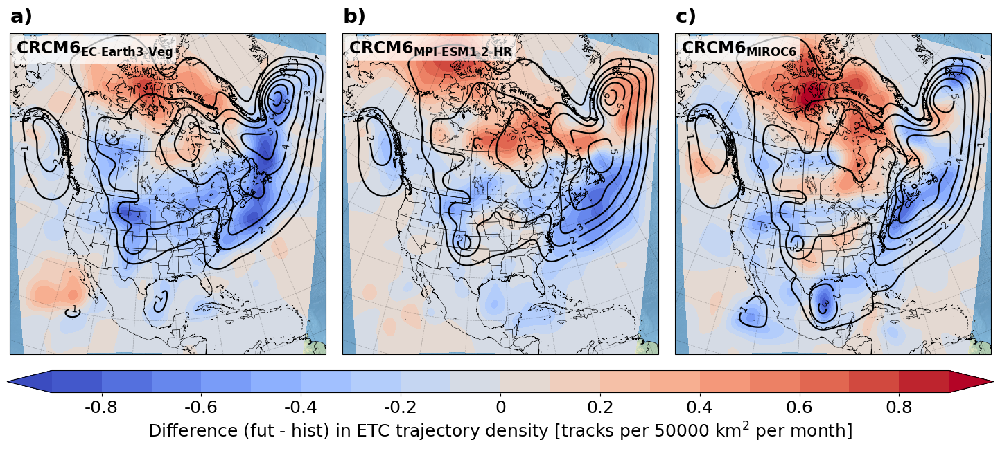

In [5]:
data_input = {}
data_hist  = {}

for sim, fut_sim in sim_hist_fut.items():

    data_input[sim] = ds_dens[fut_sim].sel(season='ALL').density_ETCs * 50000. - ds_dens[sim].sel(season='ALL').density_ETCs * 50000.
    data_hist[sim] = ds_dens[sim].sel(season='ALL').density_ETCs * 50000.

plot_map(
    data_input,
    data_hist=data_hist,
    contour_levels=list(np.arange(0, 15, 1)),
    simulations=list(data_input.keys()),
    colormap = 'coolwarm',
    vmin=-.9,
    vmax=.9,
    step=0.1,
    label = 'Difference (fut - hist) in ETC trajectory density [tracks per $50 000~\mathrm{km^2}$ per month]',
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/ETC_density_fut_vs_hist{tc_tag}.png", dpi=300, bbox_inches="tight")

## EETCs Cumulative Metric and difference between historical simulations and future simulations

Contrairement au notebook plot_map_ETCs_diff_w_hist, ici les simulations n'ont pas été regrillées sur la grille d'ERA5 car elles sont comparées entre elles et partagent une grille commune. Pour obtenir le surplus par rapport au centile, on utilise total_ext_EETCs_total qui représente le volume totale de PR ou WS dans les 1000km d'un cyclone lorsque la variable est extrême, et on y retire la valeur du centile car ce n'est pas fait en amont (pour cela, on utilise le nombre de fois qu'on a excédé le centile count_ext_EETCs_total que l'on multiplie par la valeur du centile percentile[sim, 'pr'].sel(quantile=0.99).pr).

### Precipitation

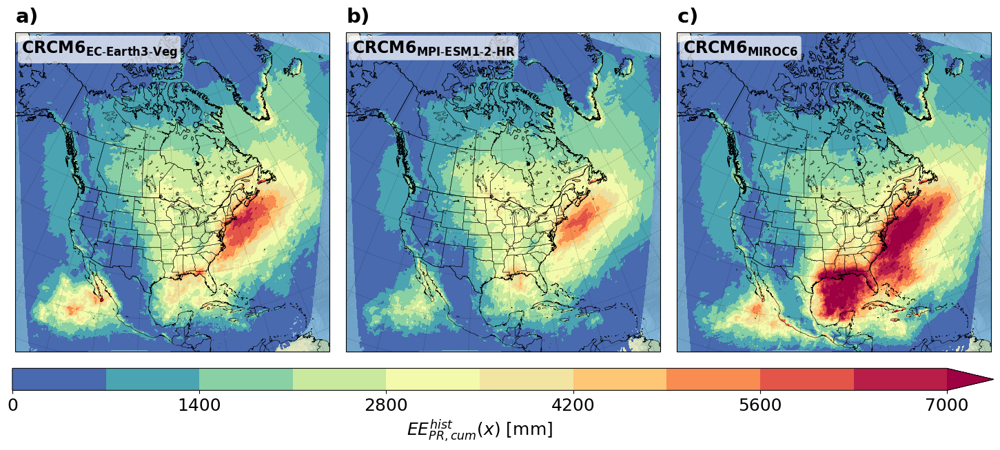

In [6]:
data_input = {}

for sim in sim_hist_fut:
    total_hist = data['total_ext_EETCs_total'][sim].sel(quantile=0.99, variable='pr')
    count_hist = data['count_ext_EETCs_total'][sim].sel(quantile=0.99, variable='pr')
    percentile_hist = percentile[sim, 'pr'].sel(quantile=0.99).pr

    data_input[sim] = total_hist - percentile_hist * count_hist

plot_map(
    data_input,
    simulations=list(data_input.keys()),
    colormap = 'Spectral_r',
    vmin=0,
    vmax=7000,
    step=700,
    label = r'$EE_{PR,cum}^{hist}(x)$ [mm]',
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/EE_hist_PR_cum{tc_tag}.png", dpi=300, bbox_inches="tight")

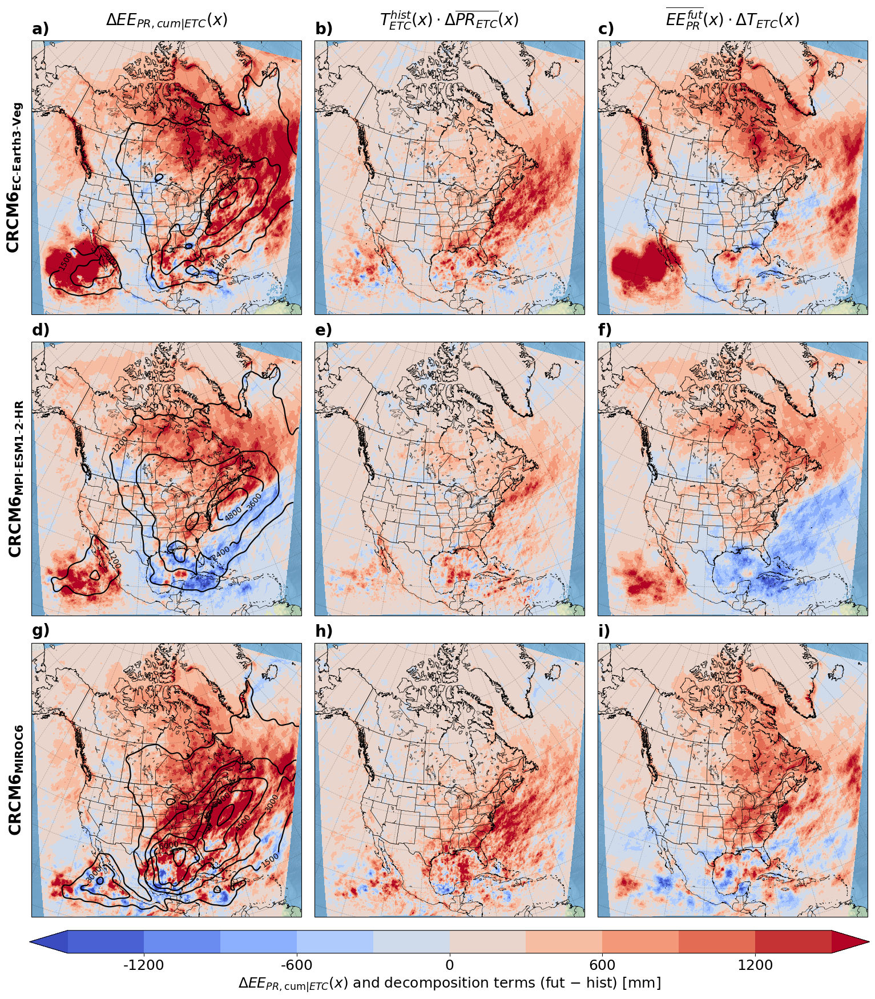

In [7]:
term_total = {}
term1 = {}
term2 = {}
term_total_hist = {}
contour_levels_term_total = {}
contour_levels_terms = {}

steps_term_total = {
    "UBD": 1500,
    "UBE": 1200,
    "UBF": 1500,
}

# steps_terms = {
#     "UBD": 750,
#     "UBE": 500,
#     "UBF": 750,
# }

for sim, fut_sim in sim_hist_fut.items():

    total_hist = data['total_ext_EETCs_total'][sim].sel(quantile=0.99, variable='pr')
    count_hist = data['count_ext_EETCs_total'][sim].sel(quantile=0.99, variable='pr')
    percentile_hist = percentile[sim, 'pr'].sel(quantile=0.99).pr
    EEcum_hist = total_hist - percentile_hist * count_hist
    term_total_hist[sim] = EEcum_hist
    
    total_fut = data['total_ext_EETCs_total'][fut_sim].sel(quantile=0.99, variable='pr')
    count_fut = data['count_ext_EETCs_total'][fut_sim].sel(quantile=0.99, variable='pr')
    EEcum_fut = total_fut - percentile_hist * count_fut
    
    diff = EEcum_fut.fillna(0) - EEcum_hist.fillna(0) # On remplace les NaN par des 0 avant la soustraction si seul un des deux à NaN (car x - NaN = NaN)
    term_total[sim] = diff.where((np.abs(EEcum_fut) > 0.) | (np.abs(EEcum_hist) > 0.)) # Les zones où AUCUN des deux n'a de cyclones redeviennent des NaN
    
    contour_levels_term_total[sim] = np.arange(-np.ceil(12000/steps_term_total[sim])*steps_term_total[sim], np.ceil(12000/steps_term_total[sim])*steps_term_total[sim] + steps_term_total[sim], steps_term_total[sim])
    # contour_levels_terms[sim] = np.arange(-np.ceil(12000/steps_terms[sim])*steps_terms[sim], np.ceil(12000/steps_terms[sim])*steps_terms[sim] + steps_terms[sim], steps_terms[sim])

    mean_fut = total_fut / count_fut
    mean_hist = total_hist / count_hist
    term1[sim] = count_hist.fillna(0) * (mean_fut.fillna(0) - mean_hist.fillna(0))     

    mean_fut_exc = (total_fut - percentile_hist * count_fut) / count_fut.where(count_fut > 0.)
    term2[sim] = mean_fut_exc.fillna(0) * (count_fut.fillna(0) - count_hist.fillna(0))

    active_points = (count_fut > 0) | (count_hist > 0) # Crée un masque qui est True si hist OU fut a eu au moins un cyclone. Si aucun cyclone alors NaN.
    term1[sim] = term1[sim].where(active_points)
    term2[sim] = term2[sim].where(active_points)

    
plot_map_three_per_three(
    [term_total, term1, term2],
    data_hist= [term_total_hist],
    contour_levels=[contour_levels_term_total],
    contour_color='k',
    sigma=7,
    simulations=list(term1.keys()),
    colormap = 'coolwarm',
    vmin=-1500,
    vmax=1500,
    step=300,
    label = r"$\Delta EE_{PR,\mathrm{cum}|ETC}(x)$ and decomposition terms (fut $-$ hist) [mm]",
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/PR_fut_vs_hist{tc_tag}.png", dpi=300, bbox_inches="tight")

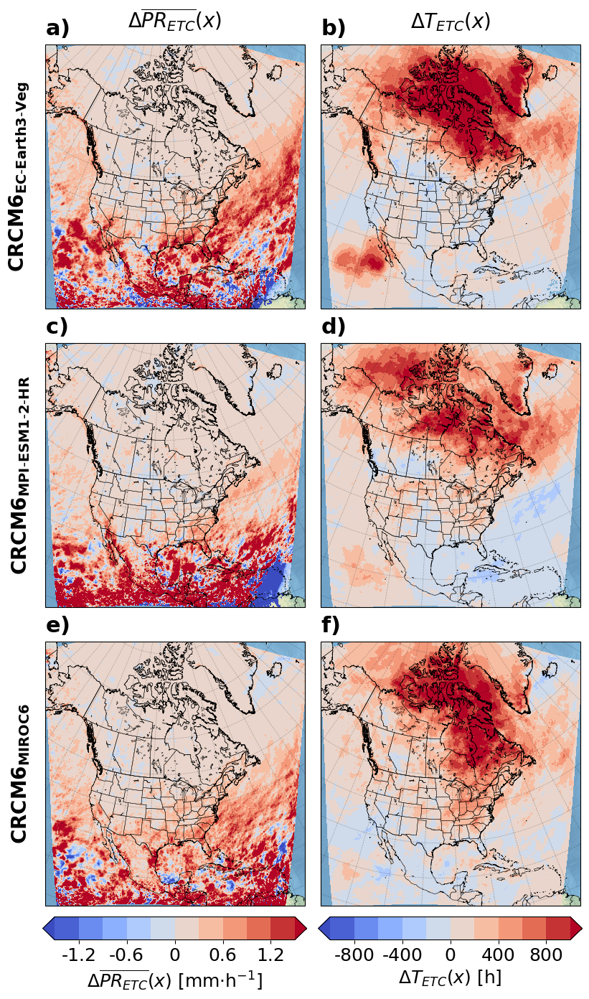

In [8]:
term1 = {}
term2 = {}
data_hist = {}
contour_levels = {}

# steps = {
#     "UBD": 750,
#     "UBE": 500,
#     "UBF": 750,
# }

for sim, fut_sim in sim_hist_fut.items():
    total_hist = data['total_ext_EETCs_total'][sim].sel(quantile=0.99, variable='pr')
    count_hist = data['count_ext_EETCs_total'][sim].sel(quantile=0.99, variable='pr')
    percentile_hist = percentile[sim, 'pr'].sel(quantile=0.99).pr
    EEcum_hist = total_hist - percentile_hist * count_hist
    
    total_fut = data['total_ext_EETCs_total'][fut_sim].sel(quantile=0.99, variable='pr')
    count_fut = data['count_ext_EETCs_total'][fut_sim].sel(quantile=0.99, variable='pr')
    EEcum_fut = total_fut - percentile_hist * count_fut
    
    diff = EEcum_fut.fillna(0) - EEcum_hist.fillna(0) # On remplace les NaN par des 0 avant la soustraction si seul un des deux à NaN (car x - NaN = NaN)
    data_hist[sim] = diff.where((np.abs(EEcum_fut) > 0.) | (np.abs(EEcum_hist) > 0.)) # Les zones où AUCUN des deux n'a de cyclones redeviennent des NaN
    
    mean_fut = total_fut / count_fut
    mean_hist = total_hist / count_hist
    term1[sim] = mean_fut.fillna(0) - mean_hist.fillna(0)  
    term2[sim] = count_fut.fillna(0) - count_hist.fillna(0)

    active_points = (count_fut > 0) | (count_hist > 0) # Crée un masque qui est True si hist OU fut a eu au moins un cyclone. Si aucun cyclone alors NaN.
    term1[sim] = term1[sim].where(active_points)
    term2[sim] = term2[sim].where(active_points)
    
    # contour_levels[sim] = np.arange(-np.ceil(5000/steps[sim])*steps[sim], np.ceil(5000/steps[sim])*steps[sim] + steps[sim], steps[sim])
    
plot_map_terms_2cbar(
    [term1, term2],
    col_cfg=[
        {"vmin": -1.5, "vmax": 1.5, "step": 0.3, "label": r'$\Delta \overline{PR_{ETC}}(x)$ [mm·h$^{-1}$]', "colormap": "coolwarm", "extend_opt": "both"},
        {"vmin": -1000, "vmax": 1000, "step": 200, "label": r'$\Delta T_{ETC}(x)$ [h]', "colormap": "coolwarm", "extend_opt": "both"}
    ],
    # data_hist=data_hist,
    # contour_levels=contour_levels,
    contour_color='k',
    sigma=7,
    simulations=list(term1.keys()),
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_terms_PR_fut_vs_hist{tc_tag}.png", dpi=300, bbox_inches="tight")

### Surface Winds

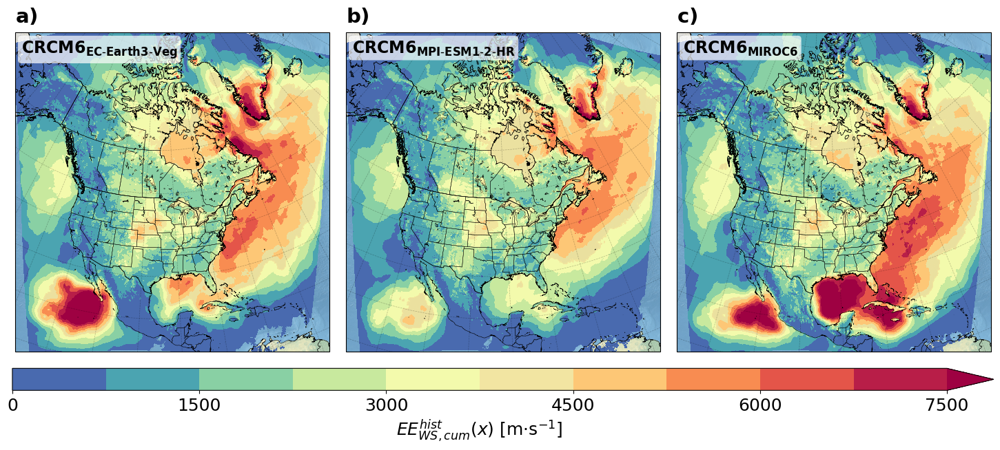

In [9]:
data_input = {}

for sim in sim_hist_fut:
    total_hist = data['total_ext_EETCs_total'][sim].sel(quantile=0.99, variable='ws')
    count_hist = data['count_ext_EETCs_total'][sim].sel(quantile=0.99, variable='ws')
    percentile_hist = percentile[sim, 'ws'].sel(quantile=0.99).surf_wind

    data_input[sim] = total_hist - percentile_hist * count_hist

plot_map(
    data_input,
    simulations=list(data_input.keys()),
    colormap = 'Spectral_r',
    vmin=0,
    vmax=7500,
    step=750,
    label = r'$EE_{WS,cum}^{hist}(x)$ [m·s$^{-1}$]',
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/EE_hist_WS_cum{tc_tag}.png", dpi=300, bbox_inches="tight")

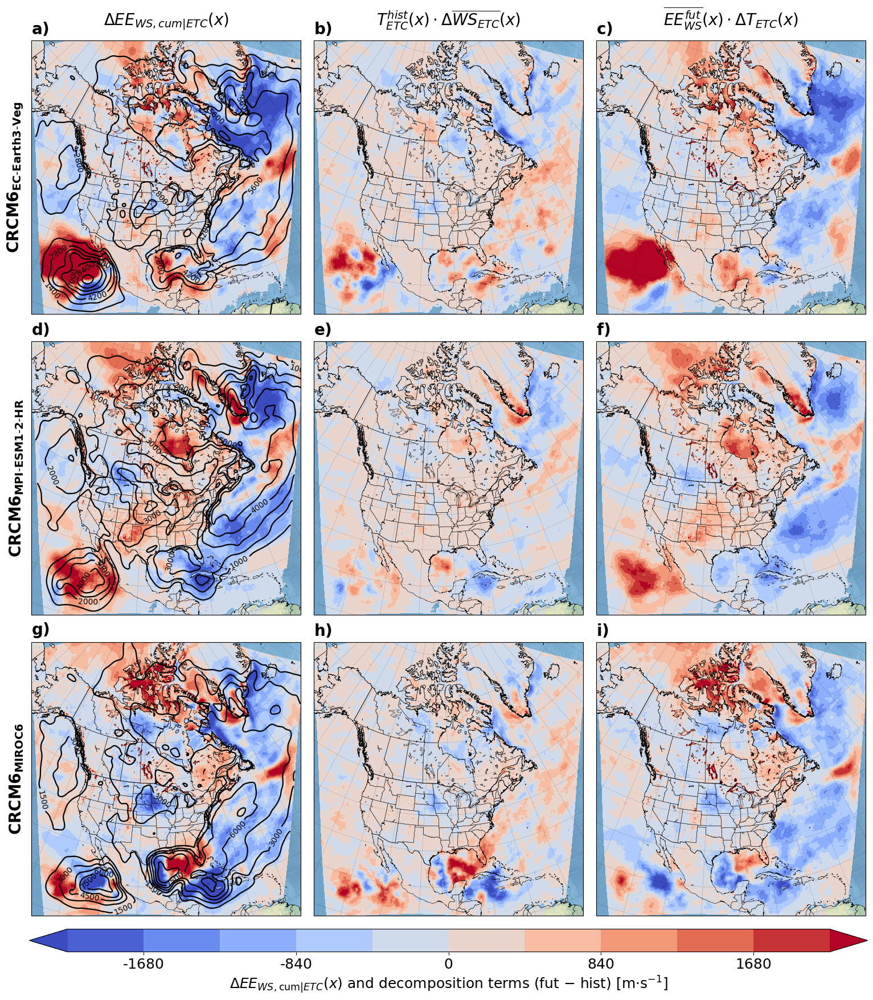

In [10]:
term_total = {}
term1 = {}
term2 = {}
term_total_hist = {}
contour_levels_term_total = {}
# contour_levels_terms = {}

steps_term_total = {
    "UBD": 1400,
    "UBE": 1000,
    "UBF": 1500,
}

# steps_terms = {
#     "UBD": 800,
#     "UBE": 800,
#     "UBF": 800,
# }

for sim, fut_sim in sim_hist_fut.items():

    total_hist = data['total_ext_EETCs_total'][sim].sel(quantile=0.99, variable='ws')
    count_hist = data['count_ext_EETCs_total'][sim].sel(quantile=0.99, variable='ws')
    percentile_hist = percentile[sim, 'ws'].sel(quantile=0.99).surf_wind
    EEcum_hist = total_hist - percentile_hist * count_hist
    term_total_hist[sim] = EEcum_hist
    
    total_fut = data['total_ext_EETCs_total'][fut_sim].sel(quantile=0.99, variable='ws')
    count_fut = data['count_ext_EETCs_total'][fut_sim].sel(quantile=0.99, variable='ws')
    EEcum_fut = total_fut - percentile_hist * count_fut
    
    diff = EEcum_fut.fillna(0) - EEcum_hist.fillna(0) # On remplace les NaN par des 0 avant la soustraction si seul un des deux à NaN (car x - NaN = NaN)
    term_total[sim] = diff.where((np.abs(EEcum_fut) > 0.) | (np.abs(EEcum_hist) > 0.)) # Les zones où AUCUN des deux n'a de cyclones redeviennent des NaN
    
    contour_levels_term_total[sim] = np.arange(-np.ceil(12000/steps_term_total[sim])*steps_term_total[sim], np.ceil(12000/steps_term_total[sim])*steps_term_total[sim] + steps_term_total[sim], steps_term_total[sim])
    # contour_levels_terms[sim] = np.arange(-np.ceil(1000/steps_terms[sim])*steps_terms[sim], np.ceil(1000/steps_terms[sim])*steps_terms[sim] + steps_terms[sim], steps_terms[sim])

    mean_fut = total_fut / count_fut
    mean_hist = total_hist / count_hist
    term1[sim] = count_hist.fillna(0) * (mean_fut.fillna(0) - mean_hist.fillna(0))     

    mean_fut_exc = (total_fut - percentile_hist * count_fut) / count_fut.where(count_fut > 0.)
    term2[sim] = mean_fut_exc.fillna(0) * (count_fut.fillna(0) - count_hist.fillna(0))

    active_points = (count_fut > 0) | (count_hist > 0) # Crée un masque qui est True si hist OU fut a eu au moins un cyclone. Si aucun cyclone alors NaN.
    term1[sim] = term1[sim].where(active_points)
    term2[sim] = term2[sim].where(active_points)

    
plot_map_three_per_three(
    [term_total, term1, term2],
    data_hist= [term_total_hist],
    contour_levels=[contour_levels_term_total],
    contour_color='k',
    sigma=6,
    simulations=list(term1.keys()),
    colormap = 'coolwarm',
    vmin=-2100,
    vmax=2100,
    step=420,
    label = r"$\Delta EE_{WS,\mathrm{cum}|ETC}(x)$ and decomposition terms (fut $-$ hist) [m·s$^{-1}$]",
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/WS_fut_vs_hist{tc_tag}.png", dpi=300, bbox_inches="tight")

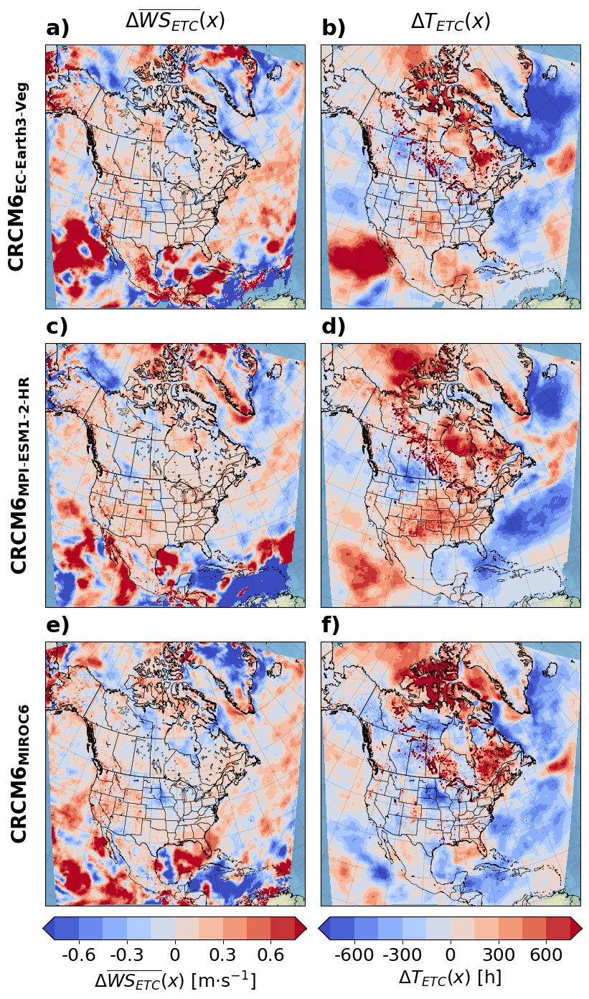

In [11]:
term1 = {}
term2 = {}
data_hist = {}
contour_levels = {}

# steps = {
#     "UBD": 800,
#     "UBE": 800,
#     "UBF": 800,
# }

for sim, fut_sim in sim_hist_fut.items():
    total_hist = data['total_ext_EETCs_total'][sim].sel(quantile=0.99, variable='ws')
    count_hist = data['count_ext_EETCs_total'][sim].sel(quantile=0.99, variable='ws')
    percentile_hist = percentile[sim, 'ws'].sel(quantile=0.99).surf_wind
    EEcum_hist = total_hist - percentile_hist * count_hist
    
    total_fut = data['total_ext_EETCs_total'][fut_sim].sel(quantile=0.99, variable='ws')
    count_fut = data['count_ext_EETCs_total'][fut_sim].sel(quantile=0.99, variable='ws')
    EEcum_fut = total_fut - percentile_hist * count_fut
    
    diff = EEcum_fut.fillna(0) - EEcum_hist.fillna(0) # On remplace les NaN par des 0 avant la soustraction si seul un des deux à NaN (car x - NaN = NaN)
    data_hist[sim] = diff.where((np.abs(EEcum_fut) > 0.) | (np.abs(EEcum_hist) > 0.)) # Les zones où AUCUN des deux n'a de cyclones redeviennent des NaN
    
    mean_fut = total_fut / count_fut
    mean_hist = total_hist / count_hist
    term1[sim] = mean_fut.fillna(0) - mean_hist.fillna(0)  
    term2[sim] = count_fut.fillna(0) - count_hist.fillna(0)

    active_points = (count_fut > 0) | (count_hist > 0) # Crée un masque qui est True si hist OU fut a eu au moins un cyclone. Si aucun cyclone alors NaN.
    term1[sim] = term1[sim].where(active_points)
    term2[sim] = term2[sim].where(active_points)
    
    # contour_levels[sim] = np.arange(-np.ceil(7000/steps[sim])*steps[sim], np.ceil(7000/steps[sim])*steps[sim] + steps[sim], steps[sim])
    
plot_map_terms_2cbar(
    [term1, term2],
    col_cfg=[
        {"vmin": -0.75, "vmax": 0.75, "step": 0.15, "label": r'$\Delta \overline{WS_{ETC}}(x)$ [m·s$^{-1}$]', "colormap": "coolwarm", "extend_opt": "both"},
        {"vmin": -750, "vmax": 750, "step": 150, "label": r'$\Delta T_{ETC}(x)$ [h]', "colormap": "coolwarm", "extend_opt": "both"}
    ],
    # data_hist=data_hist,
    # contour_levels=contour_levels,
    contour_color='k',
    sigma=7,
    simulations=list(term1.keys()),
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_terms_WS_fut_vs_hist{tc_tag}.png", dpi=300, bbox_inches="tight")

## Seasonal maps

### Track Density

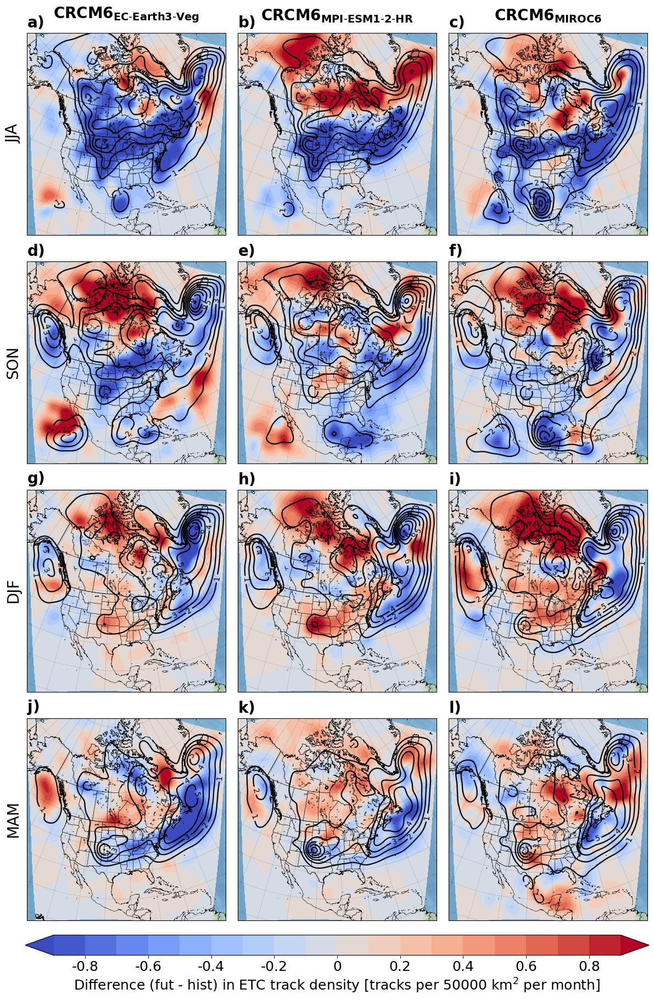

In [12]:
data_input = {}
data_hist  = {}

for sim, fut_sim in sim_hist_fut.items():
    for season in ['JJA', 'SON', 'DJF', 'MAM']:
        
        data_input[sim, season] = ds_dens[fut_sim].sel(season=season).density_ETCs * 50000. - ds_dens[sim].sel(season=season).density_ETCs * 50000.
        data_hist[sim, season] = ds_dens[sim].sel(season=season).density_ETCs * 50000.
    
plot_map_four_per_three_season(
    data_input,
    data_hist=data_hist,
    contour_levels=list(np.arange(0, 15, 1)),
    simulations=list(sim_hist_fut.keys()),
    colormap = 'coolwarm',
    vmin=-.9,
    vmax=.9,
    step=0.1,
    label = 'Difference (fut - hist) in ETC track density [tracks per $50 000~\mathrm{km^2}$ per month]',
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_seasonal_ETC_density_fut_vs_hist{tc_tag}.png", dpi=300, bbox_inches="tight")

### Precipitation

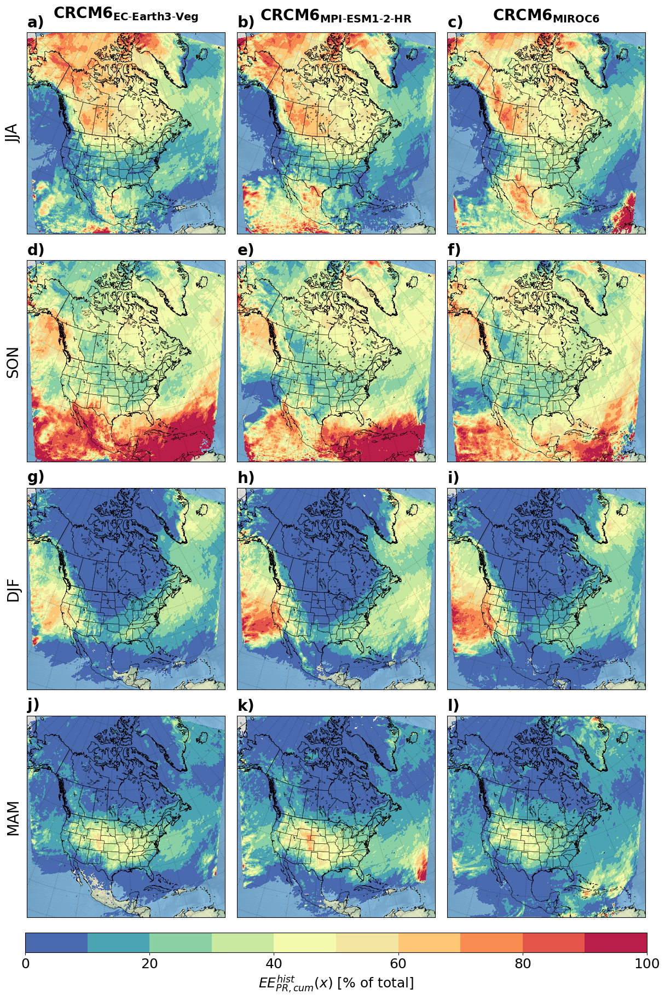

In [13]:
data_input = {}

for sim in sim_hist_fut:
    for season in ['JJA', 'SON', 'DJF', 'MAM']:
        total_hist_total = data['total_ext_EETCs_total'][sim].sel(quantile=0.99, variable='pr')
        total_hist_seasonal = data['total_ext_EETCs_seasonal'][sim].sel(season=season, quantile=0.99, variable='pr')
        
        count_hist_total = data['count_ext_EETCs_total'][sim].sel(quantile=0.99, variable='pr')
        count_hist_seasonal = data['count_ext_EETCs_seasonal'][sim].sel(season=season, quantile=0.99, variable='pr')
        
        percentile_hist = percentile[sim, 'pr'].sel(quantile=0.99).pr
        
        EE_cum_total = total_hist_total - (percentile_hist * count_hist_total)
        EE_cum_seasonal = total_hist_seasonal - (percentile_hist * count_hist_seasonal)
        
        data_input[sim, season] = (EE_cum_seasonal / EE_cum_total) * 100.
    
plot_map_four_per_three_season(
    data_input,
    simulations=list(sim_hist_fut.keys()),
    colormap = 'Spectral_r',
    vmin=0,
    vmax=100,
    step=10,
    label = r'$EE_{PR,cum}^{hist}(x)$ [% of total]',
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_seasonal_PR_hist{tc_tag}.png", dpi=300, bbox_inches="tight")

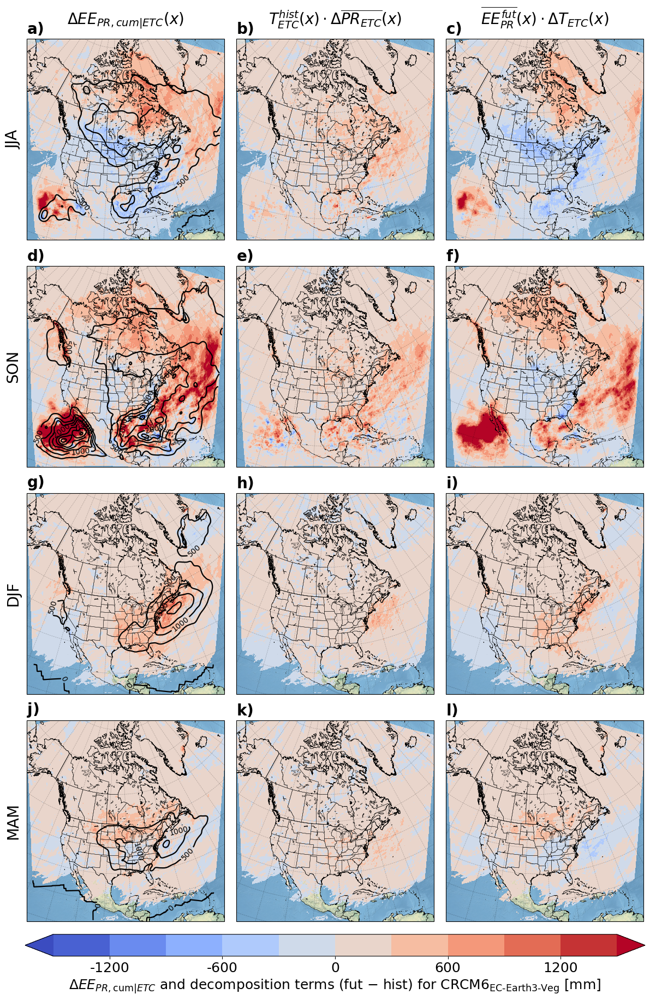

In [14]:
term_total = {}
term1 = {}
term2 = {}
term_total_hist = {}
contour_levels_term_total = {}
# contour_levels_terms = {}

steps_term_total = {
    "JJA": 500,
    "SON": 500,
    "DJF": 500,
    "MAM": 500
}

# steps_terms = 800

hist_sim, fut_sim = list(sim_hist_fut.items())[0]

for season in ['JJA', 'SON', 'DJF', 'MAM']:
    total_hist = data['total_ext_EETCs_seasonal'][hist_sim].sel(season=season, quantile=0.99, variable='pr')
    count_hist = data['count_ext_EETCs_seasonal'][hist_sim].sel(season=season, quantile=0.99, variable='pr')
    percentile_hist = percentile[hist_sim, 'pr'].sel(quantile=0.99).pr
    EEcum_hist = total_hist - percentile_hist * count_hist
    term_total_hist[season] = EEcum_hist
    
    total_fut = data['total_ext_EETCs_seasonal'][fut_sim].sel(season=season, quantile=0.99, variable='pr')
    count_fut = data['count_ext_EETCs_seasonal'][fut_sim].sel(season=season, quantile=0.99, variable='pr')
    EEcum_fut = total_fut - percentile_hist * count_fut

    diff = EEcum_fut.fillna(0) - EEcum_hist.fillna(0) # On remplace les NaN par des 0 avant la soustraction si seul un des deux à NaN (car x - NaN = NaN)
    term_total[season] = diff.where((np.abs(EEcum_fut) > 0.) | (np.abs(EEcum_hist) > 0.)) # Les zones où AUCUN des deux n'a de cyclones redeviennent des NaN

    contour_levels_term_total[season] = np.arange(-np.ceil(12000/steps_term_total[season])*steps_term_total[season], np.ceil(12000/steps_term_total[season])*steps_term_total[season] + steps_term_total[season], steps_term_total[season])
    # contour_levels_terms[season] = np.arange(-np.ceil(12000/steps_terms)*steps_terms, np.ceil(12000/steps_terms)*steps_terms + steps_terms, steps_terms)
    
    mean_fut = total_fut / count_fut
    mean_hist = total_hist / count_hist
    term1[season] = count_hist.fillna(0) * (mean_fut.fillna(0) - mean_hist.fillna(0))     

    mean_fut_exc = (total_fut - percentile_hist * count_fut) / count_fut.where(count_fut > 0.)
    term2[season] = mean_fut_exc.fillna(0) * (count_fut.fillna(0) - count_hist.fillna(0))

    active_points = (count_fut > 0) | (count_hist > 0) # Crée un masque qui est True si hist OU fut a eu au moins un cyclone. Si aucun cyclone alors NaN.
    term1[season] = term1[season].where(active_points)
    term2[season] = term2[season].where(active_points)
    
plot_map_four_per_three(
    [term_total, term1, term2],
    data_hist= [term_total_hist],
    contour_levels=[contour_levels_term_total],
    contour_color='k',
    sigma=7,
    colormap = 'coolwarm',
    vmin=-1500,
    vmax=1500,
    step=300,
    label = rf"$\Delta EE_{{PR,\mathrm{{cum}}|ETC}}$ and decomposition terms (fut $-$ hist) for {sim_label_nobold[hist_sim]} [mm]",
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_seasonal_PR_CRCM6_EC-Earth3-Veg_fut_vs_hist{tc_tag}.png", dpi=300, bbox_inches="tight")

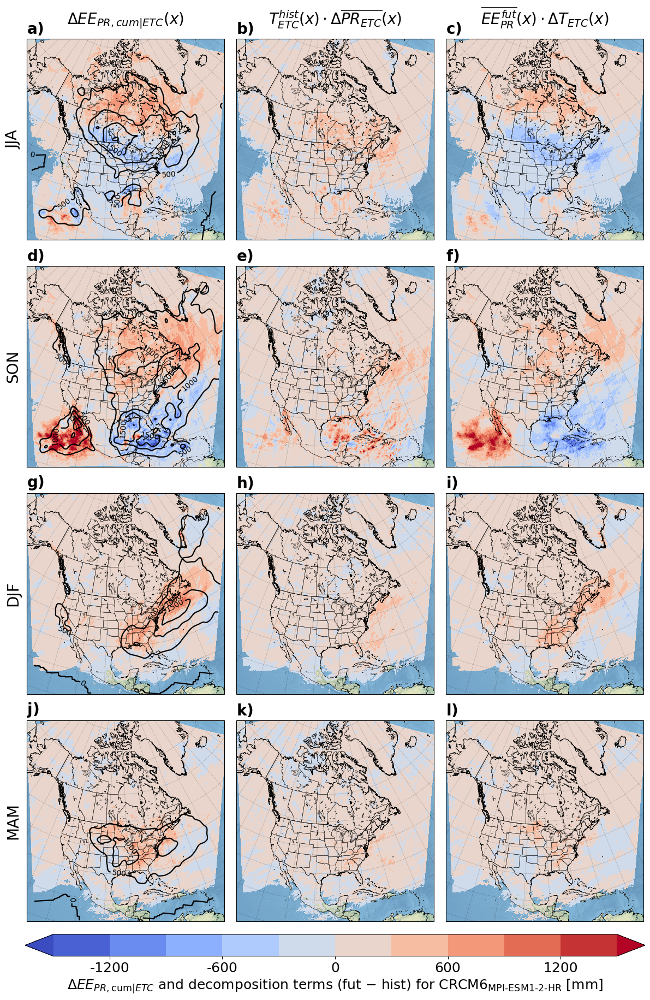

In [15]:
term_total = {}
term1 = {}
term2 = {}
term_total_hist = {}
contour_levels_term_total = {}
# contour_levels_terms = {}

steps_term_total = {
    "JJA": 500,
    "SON": 500,
    "DJF": 500,
    "MAM": 500
}

# steps_terms = 800

hist_sim, fut_sim = list(sim_hist_fut.items())[1]

for season in ['JJA', 'SON', 'DJF', 'MAM']:
    total_hist = data['total_ext_EETCs_seasonal'][hist_sim].sel(season=season, quantile=0.99, variable='pr')
    count_hist = data['count_ext_EETCs_seasonal'][hist_sim].sel(season=season, quantile=0.99, variable='pr')
    percentile_hist = percentile[hist_sim, 'pr'].sel(quantile=0.99).pr
    EEcum_hist = total_hist - percentile_hist * count_hist
    term_total_hist[season] = EEcum_hist
    
    total_fut = data['total_ext_EETCs_seasonal'][fut_sim].sel(season=season, quantile=0.99, variable='pr')
    count_fut = data['count_ext_EETCs_seasonal'][fut_sim].sel(season=season, quantile=0.99, variable='pr')
    EEcum_fut = total_fut - percentile_hist * count_fut
    
    diff = EEcum_fut.fillna(0) - EEcum_hist.fillna(0) # On remplace les NaN par des 0 avant la soustraction si seul un des deux à NaN (car x - NaN = NaN)
    term_total[season] = diff.where((np.abs(EEcum_fut) > 0.) | (np.abs(EEcum_hist) > 0.)) # Les zones où AUCUN des deux n'a de cyclones redeviennent des NaN
    
    contour_levels_term_total[season] = np.arange(-np.ceil(12000/steps_term_total[season])*steps_term_total[season], np.ceil(12000/steps_term_total[season])*steps_term_total[season] + steps_term_total[season], steps_term_total[season])
    # contour_levels_terms[season] = np.arange(-np.ceil(12000/steps_terms)*steps_terms, np.ceil(12000/steps_terms)*steps_terms + steps_terms, steps_terms)
    
    mean_fut = total_fut / count_fut
    mean_hist = total_hist / count_hist
    term1[season] = count_hist.fillna(0) * (mean_fut.fillna(0) - mean_hist.fillna(0))     

    mean_fut_exc = (total_fut - percentile_hist * count_fut) / count_fut.where(count_fut > 0.)
    term2[season] = mean_fut_exc.fillna(0) * (count_fut.fillna(0) - count_hist.fillna(0))

    active_points = (count_fut > 0) | (count_hist > 0) # Crée un masque qui est True si hist OU fut a eu au moins un cyclone. Si aucun cyclone alors NaN.
    term1[season] = term1[season].where(active_points)
    term2[season] = term2[season].where(active_points)
    
plot_map_four_per_three(
    [term_total, term1, term2],
    data_hist= [term_total_hist],
    contour_levels=[contour_levels_term_total],
    contour_color='k',
    sigma=7,
    colormap = 'coolwarm',
    vmin=-1500,
    vmax=1500,
    step=300,
    label = rf"$\Delta EE_{{PR,\mathrm{{cum}}|ETC}}$ and decomposition terms (fut $-$ hist) for {sim_label_nobold[hist_sim]} [mm]",
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_seasonal_PR_CRCM6_MPI-ESM1-2-HR_fut_vs_hist{tc_tag}.png", dpi=300, bbox_inches="tight")

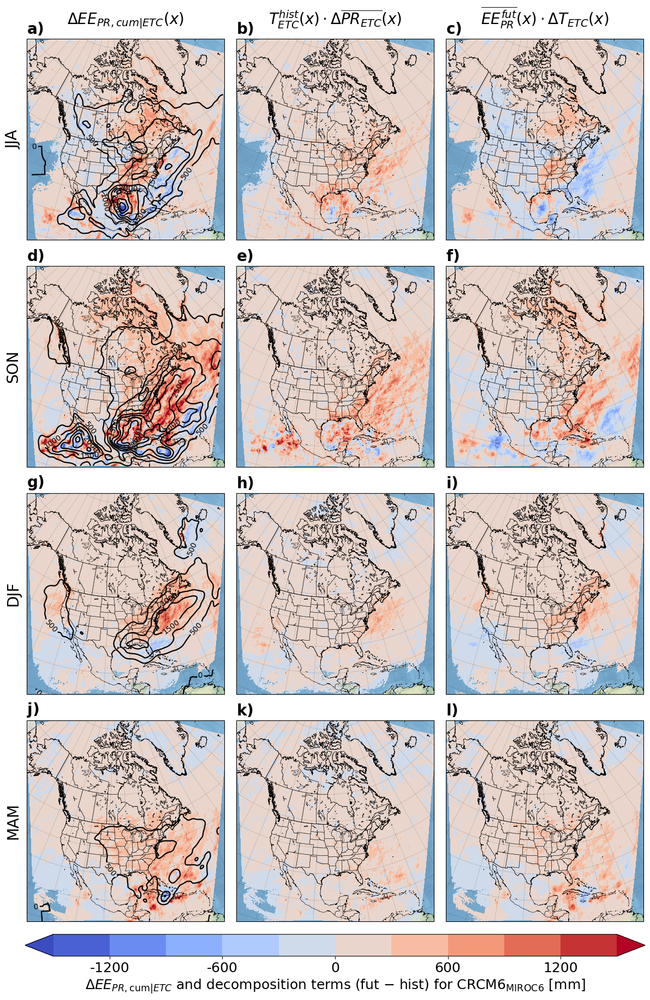

In [16]:
term_total = {}
term1 = {}
term2 = {}
term_total_hist = {}
contour_levels_term_total = {}
# contour_levels_terms = {}

steps_term_total = {
    "JJA": 500,
    "SON": 500,
    "DJF": 500,
    "MAM": 500
}

# steps_terms = 800

hist_sim, fut_sim = list(sim_hist_fut.items())[2]

for season in ['JJA', 'SON', 'DJF', 'MAM']:
    total_hist = data['total_ext_EETCs_seasonal'][hist_sim].sel(season=season, quantile=0.99, variable='pr')
    count_hist = data['count_ext_EETCs_seasonal'][hist_sim].sel(season=season, quantile=0.99, variable='pr')
    percentile_hist = percentile[hist_sim, 'pr'].sel(quantile=0.99).pr
    EEcum_hist = total_hist - percentile_hist * count_hist
    term_total_hist[season] = EEcum_hist
    
    total_fut = data['total_ext_EETCs_seasonal'][fut_sim].sel(season=season, quantile=0.99, variable='pr')
    count_fut = data['count_ext_EETCs_seasonal'][fut_sim].sel(season=season, quantile=0.99, variable='pr')
    EEcum_fut = total_fut - percentile_hist * count_fut
    
    diff = EEcum_fut.fillna(0) - EEcum_hist.fillna(0) # On remplace les NaN par des 0 avant la soustraction si seul un des deux à NaN (car x - NaN = NaN)
    term_total[season] = diff.where((np.abs(EEcum_fut) > 0.) | (np.abs(EEcum_hist) > 0.)) # Les zones où AUCUN des deux n'a de cyclones redeviennent des NaN
        
    contour_levels_term_total[season] = np.arange(-np.ceil(12000/steps_term_total[season])*steps_term_total[season], np.ceil(12000/steps_term_total[season])*steps_term_total[season] + steps_term_total[season], steps_term_total[season])
    # contour_levels_terms[season] = np.arange(-np.ceil(12000/steps_terms)*steps_terms, np.ceil(12000/steps_terms)*steps_terms + steps_terms, steps_terms)
    
    mean_fut = total_fut / count_fut
    mean_hist = total_hist / count_hist
    term1[season] = count_hist.fillna(0) * (mean_fut.fillna(0) - mean_hist.fillna(0))     

    mean_fut_exc = (total_fut - percentile_hist * count_fut) / count_fut.where(count_fut > 0.)
    term2[season] = mean_fut_exc.fillna(0) * (count_fut.fillna(0) - count_hist.fillna(0))

    active_points = (count_fut > 0) | (count_hist > 0) # Crée un masque qui est True si hist OU fut a eu au moins un cyclone. Si aucun cyclone alors NaN.
    term1[season] = term1[season].where(active_points)
    term2[season] = term2[season].where(active_points)
    
plot_map_four_per_three(
    [term_total, term1, term2],
    data_hist= [term_total_hist],
    contour_levels=[contour_levels_term_total],
    contour_color='k',
    sigma=7,
    colormap = 'coolwarm',
    vmin=-1500,
    vmax=1500,
    step=300,
    label = rf"$\Delta EE_{{PR,\mathrm{{cum}}|ETC}}$ and decomposition terms (fut $-$ hist) for {sim_label_nobold[hist_sim]} [mm]",
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_seasonal_PR_CRCM6_MIROC6_fut_vs_hist{tc_tag}.png", dpi=300, bbox_inches="tight")

### Surface Winds

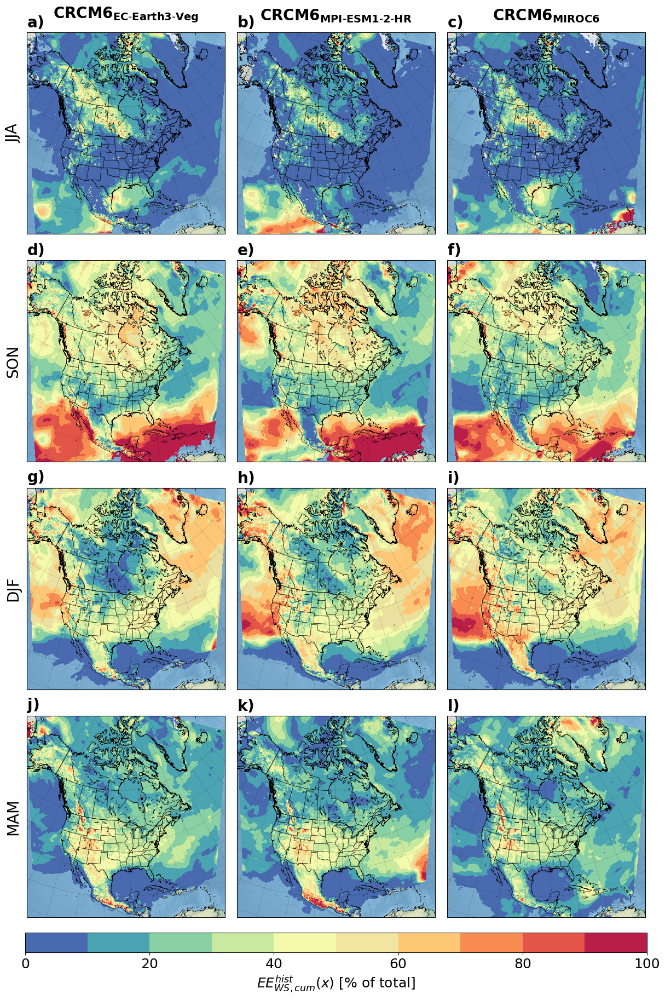

In [17]:
data_input = {}

for sim in sim_hist_fut:
    for season in ['JJA', 'SON', 'DJF', 'MAM']:
        total_hist_total = data['total_ext_EETCs_total'][sim].sel(quantile=0.99, variable='ws')
        total_hist_seasonal = data['total_ext_EETCs_seasonal'][sim].sel(season=season, quantile=0.99, variable='ws')
        
        count_hist_total = data['count_ext_EETCs_total'][sim].sel(quantile=0.99, variable='ws')
        count_hist_seasonal = data['count_ext_EETCs_seasonal'][sim].sel(season=season, quantile=0.99, variable='ws')
        
        percentile_hist = percentile[sim, 'ws'].sel(quantile=0.99).surf_wind
        
        EE_cum_total = total_hist_total - (percentile_hist * count_hist_total)
        EE_cum_seasonal = total_hist_seasonal - (percentile_hist * count_hist_seasonal)
        
        data_input[sim, season] = (EE_cum_seasonal / EE_cum_total) * 100.
    
plot_map_four_per_three_season(
    data_input,
    simulations=list(sim_hist_fut.keys()),
    colormap = 'Spectral_r',
    vmin=0,
    vmax=100,
    step=10,
    label = r'$EE_{WS,cum}^{hist}(x)$ [% of total]',
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_seasonal_WS_hist{tc_tag}.png", dpi=300, bbox_inches="tight")

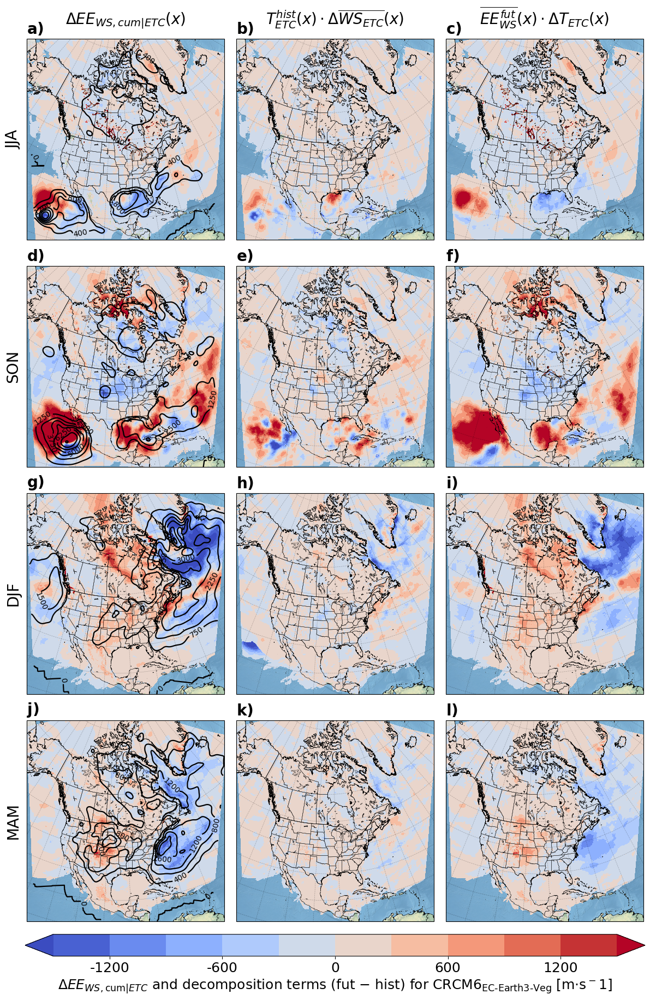

In [18]:
term_total = {}
term1 = {}
term2 = {}
term_total_hist = {}
contour_levels_term_total = {}
# contour_levels_terms = {}

steps_term_total = {
    "JJA": 400,
    "SON": 1250,
    "DJF": 750,
    "MAM": 400
}

# steps_terms = 800

hist_sim, fut_sim = list(sim_hist_fut.items())[0]

for season in ['JJA', 'SON', 'DJF', 'MAM']:
    total_hist = data['total_ext_EETCs_seasonal'][hist_sim].sel(season=season, quantile=0.99, variable='ws')
    count_hist = data['count_ext_EETCs_seasonal'][hist_sim].sel(season=season, quantile=0.99, variable='ws')
    percentile_hist = percentile[hist_sim, 'ws'].sel(quantile=0.99).surf_wind
    EEcum_hist = total_hist - percentile_hist * count_hist
    term_total_hist[season] = EEcum_hist
    
    total_fut = data['total_ext_EETCs_seasonal'][fut_sim].sel(season=season, quantile=0.99, variable='ws')
    count_fut = data['count_ext_EETCs_seasonal'][fut_sim].sel(season=season, quantile=0.99, variable='ws')
    EEcum_fut = total_fut - percentile_hist * count_fut
    
    diff = EEcum_fut.fillna(0) - EEcum_hist.fillna(0) # On remplace les NaN par des 0 avant la soustraction si seul un des deux à NaN (car x - NaN = NaN)
    term_total[season] = diff.where((np.abs(EEcum_fut) > 0.) | (np.abs(EEcum_hist) > 0.)) # Les zones où AUCUN des deux n'a de cyclones redeviennent des NaN
         
    contour_levels_term_total[season] = np.arange(-np.ceil(12000/steps_term_total[season])*steps_term_total[season], np.ceil(12000/steps_term_total[season])*steps_term_total[season] + steps_term_total[season], steps_term_total[season])
    # contour_levels_terms[season] = np.arange(-np.ceil(12000/steps_terms)*steps_terms, np.ceil(12000/steps_terms)*steps_terms + steps_terms, steps_terms)
    
    mean_fut = total_fut / count_fut
    mean_hist = total_hist / count_hist
    term1[season] = count_hist.fillna(0) * (mean_fut.fillna(0) - mean_hist.fillna(0))     

    mean_fut_exc = (total_fut - percentile_hist * count_fut) / count_fut.where(count_fut > 0.)
    term2[season] = mean_fut_exc.fillna(0) * (count_fut.fillna(0) - count_hist.fillna(0))

    active_points = (count_fut > 0) | (count_hist > 0) # Crée un masque qui est True si hist OU fut a eu au moins un cyclone. Si aucun cyclone alors NaN.
    term1[season] = term1[season].where(active_points)
    term2[season] = term2[season].where(active_points)
    
plot_map_four_per_three(
    [term_total, term1, term2],
    data_hist= [term_total_hist],
    contour_levels=[contour_levels_term_total],
    contour_color='k',
    sigma=7,
    colormap = 'coolwarm',
    vmin=-1500,
    vmax=1500,
    step=300,
    label = rf"$\Delta EE_{{WS,\mathrm{{cum}}|ETC}}$ and decomposition terms (fut $-$ hist) for {sim_label_nobold[hist_sim]} [m$\cdot$s$^{-1}$]",
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_seasonal_WS_CRCM6_EC-Earth3-Veg_fut_vs_hist{tc_tag}.png", dpi=300, bbox_inches="tight")

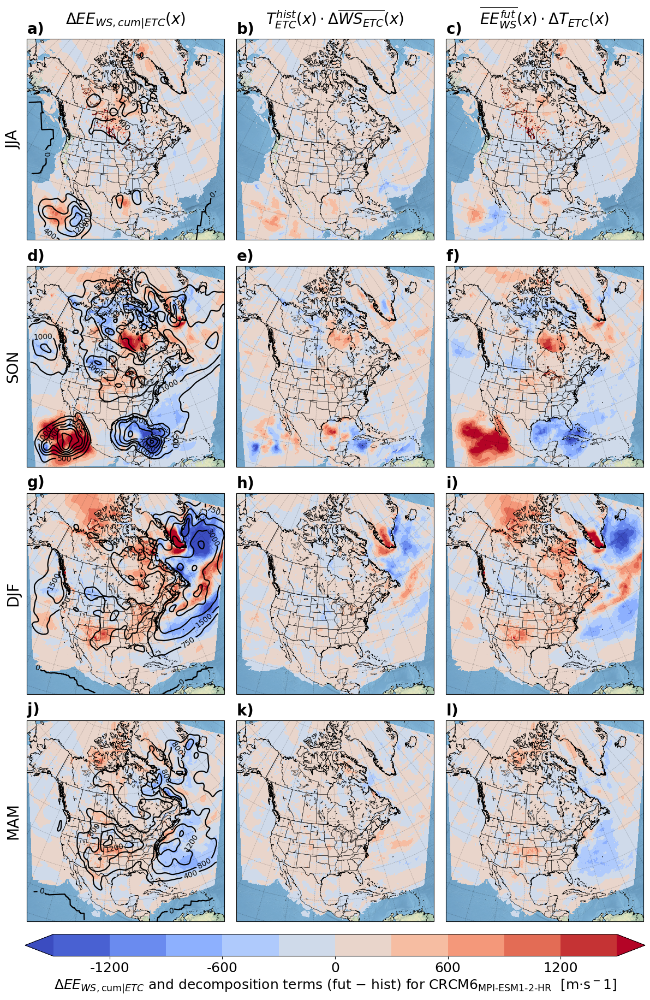

In [5]:
term_total = {}
term1 = {}
term2 = {}
term_total_hist = {}
contour_levels_term_total = {}
# contour_levels_terms = {}

steps_term_total = {
    "JJA": 400,
    "SON": 500,
    "DJF": 750,
    "MAM": 400
}

# steps_terms = 800

hist_sim, fut_sim = list(sim_hist_fut.items())[1]

for season in ['JJA', 'SON', 'DJF', 'MAM']:
    total_hist = data['total_ext_EETCs_seasonal'][hist_sim].sel(season=season, quantile=0.99, variable='ws')
    count_hist = data['count_ext_EETCs_seasonal'][hist_sim].sel(season=season, quantile=0.99, variable='ws')
    percentile_hist = percentile[hist_sim, 'ws'].sel(quantile=0.99).surf_wind
    EEcum_hist = total_hist - percentile_hist * count_hist
    term_total_hist[season] = EEcum_hist
    
    total_fut = data['total_ext_EETCs_seasonal'][fut_sim].sel(season=season, quantile=0.99, variable='ws')
    count_fut = data['count_ext_EETCs_seasonal'][fut_sim].sel(season=season, quantile=0.99, variable='ws')
    EEcum_fut = total_fut - percentile_hist * count_fut
    
    diff = EEcum_fut.fillna(0) - EEcum_hist.fillna(0) # On remplace les NaN par des 0 avant la soustraction si seul un des deux à NaN (car x - NaN = NaN)
    term_total[season] = diff.where((np.abs(EEcum_fut) > 0.) | (np.abs(EEcum_hist) > 0.)) # Les zones où AUCUN des deux n'a de cyclones redeviennent des NaN
         
    contour_levels_term_total[season] = np.arange(-np.ceil(12000/steps_term_total[season])*steps_term_total[season], np.ceil(12000/steps_term_total[season])*steps_term_total[season] + steps_term_total[season], steps_term_total[season])
    # contour_levels_terms[season] = np.arange(-np.ceil(12000/steps_terms)*steps_terms, np.ceil(12000/steps_terms)*steps_terms + steps_terms, steps_terms)
    
    mean_fut = total_fut / count_fut
    mean_hist = total_hist / count_hist
    term1[season] = count_hist.fillna(0) * (mean_fut.fillna(0) - mean_hist.fillna(0))     

    mean_fut_exc = (total_fut - percentile_hist * count_fut) / count_fut.where(count_fut > 0.)
    term2[season] = mean_fut_exc.fillna(0) * (count_fut.fillna(0) - count_hist.fillna(0))

    active_points = (count_fut > 0) | (count_hist > 0) # Crée un masque qui est True si hist OU fut a eu au moins un cyclone. Si aucun cyclone alors NaN.
    term1[season] = term1[season].where(active_points)
    term2[season] = term2[season].where(active_points)
    
plot_map_four_per_three(
    [term_total, term1, term2],
    data_hist= [term_total_hist],
    contour_levels=[contour_levels_term_total],
    contour_color='k',
    sigma=7,
    colormap = 'coolwarm',
    vmin=-1500,
    vmax=1500,
    step=300,
    label = rf"$\Delta EE_{{WS,\mathrm{{cum}}|ETC}}$ and decomposition terms (fut $-$ hist) for {sim_label_nobold[hist_sim]}  [m$\cdot$s$^{-1}$]",
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_seasonal_WS_CRCM6_MPI-ESM1-2-HR_fut_vs_hist{tc_tag}.png", dpi=300, bbox_inches="tight")

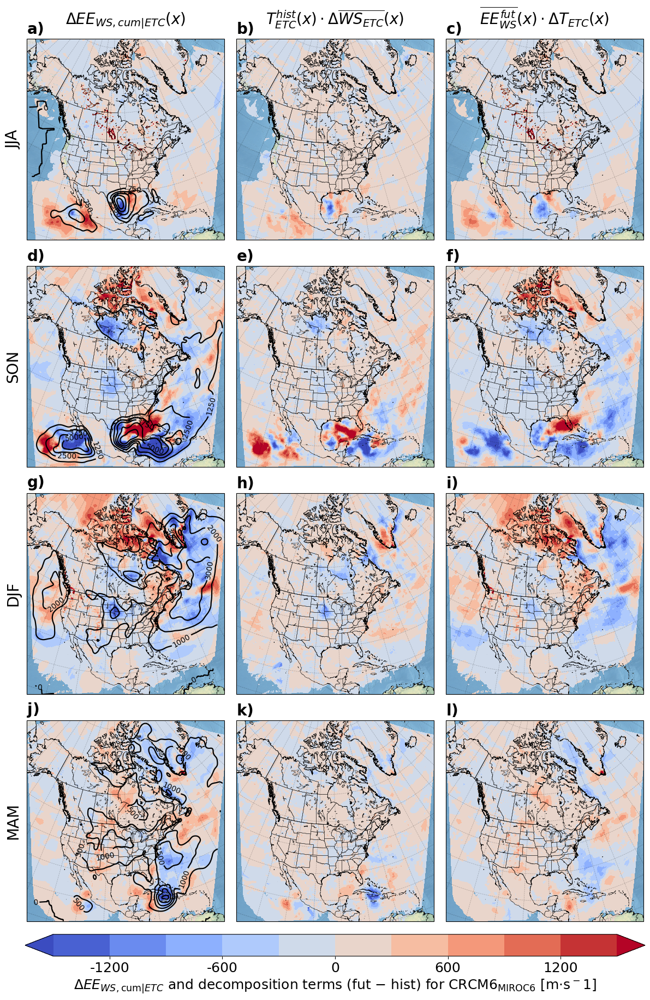

In [6]:
term_total = {}
term1 = {}
term2 = {}
term_total_hist = {}
contour_levels_term_total = {}
# contour_levels_terms = {}

steps_term_total = {
    "JJA": 750,
    "SON": 1250,
    "DJF": 1000,
    "MAM": 500
}

# steps_terms = 800

hist_sim, fut_sim = list(sim_hist_fut.items())[2]

for season in ['JJA', 'SON', 'DJF', 'MAM']:
    total_hist = data['total_ext_EETCs_seasonal'][hist_sim].sel(season=season, quantile=0.99, variable='ws')
    count_hist = data['count_ext_EETCs_seasonal'][hist_sim].sel(season=season, quantile=0.99, variable='ws')
    percentile_hist = percentile[hist_sim, 'ws'].sel(quantile=0.99).surf_wind
    EEcum_hist = total_hist - percentile_hist * count_hist
    term_total_hist[season] = EEcum_hist
    
    total_fut = data['total_ext_EETCs_seasonal'][fut_sim].sel(season=season, quantile=0.99, variable='ws')
    count_fut = data['count_ext_EETCs_seasonal'][fut_sim].sel(season=season, quantile=0.99, variable='ws')
    EEcum_fut = total_fut - percentile_hist * count_fut
    
    diff = EEcum_fut.fillna(0) - EEcum_hist.fillna(0) # On remplace les NaN par des 0 avant la soustraction si seul un des deux à NaN (car x - NaN = NaN)
    term_total[season] = diff.where((np.abs(EEcum_fut) > 0.) | (np.abs(EEcum_hist) > 0.)) # Les zones où AUCUN des deux n'a de cyclones redeviennent des NaN
         
    contour_levels_term_total[season] = np.arange(-np.ceil(12000/steps_term_total[season])*steps_term_total[season], np.ceil(12000/steps_term_total[season])*steps_term_total[season] + steps_term_total[season], steps_term_total[season])
    # contour_levels_terms[season] = np.arange(-np.ceil(12000/steps_terms)*steps_terms, np.ceil(12000/steps_terms)*steps_terms + steps_terms, steps_terms)
    
    mean_fut = total_fut / count_fut
    mean_hist = total_hist / count_hist
    term1[season] = count_hist.fillna(0) * (mean_fut.fillna(0) - mean_hist.fillna(0))     

    mean_fut_exc = (total_fut - percentile_hist * count_fut) / count_fut.where(count_fut > 0.)
    term2[season] = mean_fut_exc.fillna(0) * (count_fut.fillna(0) - count_hist.fillna(0))

    active_points = (count_fut > 0) | (count_hist > 0) # Crée un masque qui est True si hist OU fut a eu au moins un cyclone. Si aucun cyclone alors NaN.
    term1[season] = term1[season].where(active_points)
    term2[season] = term2[season].where(active_points)
    
plot_map_four_per_three(
    [term_total, term1, term2],
    data_hist= [term_total_hist],
    contour_levels=[contour_levels_term_total],
    contour_color='k',
    sigma=7,
    colormap = 'coolwarm',
    vmin=-1500,
    vmax=1500,
    step=300,
    label = rf"$\Delta EE_{{WS,\mathrm{{cum}}|ETC}}$ and decomposition terms (fut $-$ hist) for {sim_label_nobold[hist_sim]} [m·s$^{-1}$]",
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_seasonal_WS_CRCM6_MIROC6_fut_vs_hist{tc_tag}.png", dpi=300, bbox_inches="tight")

## For testing the template

In [ ]:
positions = [
    [0.05, 0.10, 0.29, 0.29],  # Rangée du haut, Colonne 1
    [0.35, 0.10, 0.29, 0.29],  # Rangée du haut, Colonne 2
    [0.65, 0.10, 0.29, 0.29],  # Rangée du haut, Colonne 3
]

sim_label = [
    # r'ERA5',
    r'CRCM6$_{\mathbf{ERA5}}$',
    r'CRCM6$_{\mathbf{EC\text{-}Earth3\text{-}Veg}}$',
    r'CRCM6$_{\mathbf{MPI\text{-}ESM1\text{-}2\text{-}HR}}$',
    r'CRCM6$_{\mathbf{MIROC6}}$'
]

lon = np.linspace(-80, -50, 10)
lat = np.linspace(40, 60, 10)
lon2d, lat2d = np.meshgrid(lon, lat)

# Data aléatoire
dummy_data = np.random.uniform(0, 10, size=(10, 10))
dummy_data_2 = np.random.uniform(-10, 10, size=(10, 10))

plotcrs = ccrs.LambertConformal(central_latitude=45, central_longitude=-95)
fig = plt.figure(figsize=(16, 16))
axes = [fig.add_axes(pos, projection=plotcrs) for pos in positions]

for i, ax in enumerate(axes):
    
    crs = ccrs.PlateCarree()

    # ax.set_extent([-130, -51, 77, 13], crs=ccrs.PlateCarree())
    ax.set_extent([-128, -56, 81, 12], crs=ccrs.PlateCarree())
    ax.coastlines(resolution='10m', linewidth=0.4, color='black')
    
    ax.text(0.02, 0.98, sim_label[i], transform=ax.transAxes, fontsize=17, fontweight='bold',
            ha='left', va='top', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2'))

    sc = ax.contourf(
        lon2d, lat2d, dummy_data,
        levels=np.arange(0,12,2.5),
        cmap='Spectral_r', vmin=0, vmax=10, extend='both'
    )
    
    letter = f"$\\mathbf{{{chr(97+i)})}}$"
    ax.text(
        0, 1.02,
        letter,
        transform=ax.transAxes,
        fontsize=21,
        ha='left',
        va='bottom'
    )

left_min = min(pos[0] for pos in positions)
left_max = max(pos[0] + pos[3] for pos in positions)
cbar_ax = fig.add_axes([left_min, 0.065, left_max - left_min, 0.02])

cbar = fig.colorbar(sc, cax=cbar_ax, orientation="horizontal", pad=0.02)
cbar.set_label('ETST', fontsize=18)
cbar.ax.tick_params(labelsize=18)

In [ ]:
# --------- PARAMÈTRES FACILES À MODIFIER ----------
ncols = 2
nrows = 3    

positions = [
    [0.0,  0.57, 0.23, 0.23],
    [0.24, 0.57, 0.23, 0.23],

    [0.0,  0.31, 0.23, 0.23],
    [0.24, 0.31, 0.23, 0.23],

    [0.0,  0.05, 0.23, 0.23],
    [0.24, 0.05, 0.23, 0.23],
]

ax_width  = positions[0][2]
ax_height = positions[0][3]
left_margin = min(p[0] for p in positions)
bottom_margin = min(p[1] for p in positions)
top_margin = 1 - max(p[1] + p[3] for p in positions)
right_margin = 1 - max(p[0] + p[2] for p in positions)

var_label = "PR"
    
term_labels = [
    r"$T_{ETC}^{hist}(x) \cdot \Delta \overline{" + var_label + "_{ETC}}(x)$",
    # r"$- T_{ETC}^{hist}(x) \cdot \Delta {" + var_label + "}_{th}(x)$",
    r"$\overline{EE_{" + var_label + "}^{fut}}(x) \cdot \Delta T_{ETC}(x)$"
]
    
sim_label = [
    r'CRCM6$_{\mathbf{EC\text{-}Earth3\text{-}Veg}}$',
    r'CRCM6$_{\mathbf{MPI\text{-}ESM1\text{-}2\text{-}HR}}$',
    r'CRCM6$_{\mathbf{MIROC6}}$'
]

lon = np.linspace(-80, -50, 10)
lat = np.linspace(40, 60, 10)
lon2d, lat2d = np.meshgrid(lon, lat)

# Data aléatoire
dummy_data = np.random.uniform(0, 10, size=(10, 10))
dummy_data_2 = np.random.uniform(-10, 10, size=(10, 10))

plotcrs = ccrs.LambertConformal(central_latitude=45, central_longitude=-95)
fig = plt.figure(figsize=(16, 16))
axes = [fig.add_axes(pos, projection=plotcrs) for pos in positions]
crs = ccrs.PlateCarree()

# Ajout titres de colonnes (termes)
for col in range(ncols):
    # Centrer au-dessus de la colonne
    left = positions[col][0] + ax_width/2
    top = 1 - top_margin + 0.01  # juste au-dessus du top margin
    fig.text(left, top, term_labels[col], ha='center', va='bottom', fontsize=20, fontweight='bold')

# Ajout titres de lignes (modèles), vertical à gauche
for row in range(nrows):
    # Prendre la première colonne de chaque ligne
    left = left_margin - 0.01  # juste à gauche du plot
    bottom = positions[row*ncols][1] + ax_height/2
    fig.text(left, bottom, sim_label[row], ha='right', va='center', fontsize=20, fontweight='bold', rotation=90)

    
for i, ax in enumerate(axes):
    
    # ax.set_extent([-130, -51, 77, 13], crs=ccrs.PlateCarree())
    ax.set_extent([-128, -56, 81, 12], crs=ccrs.PlateCarree())
    ax.coastlines(resolution='10m', linewidth=0.4, color='black')
    
    label = sim_label[i // 3]
    
    # ax.text(0.02, 0.98, label,
    #         transform=ax.transAxes, fontsize=17, fontweight='bold',
    #         ha='left', va='top',
    #         bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2'))

    sc = ax.contourf(
        lon2d, lat2d, dummy_data,
        levels=np.arange(0,12,2.5),
        cmap='Spectral_r', vmin=0, vmax=10, extend='max'
    )
    
    letter = f"$\\mathbf{{{chr(97+i)})}}$"
    ax.text(
        0, 1.01,
        letter,
        transform=ax.transAxes,
        fontsize=20,
        ha='left',
        va='bottom'
    )

left_min = min(pos[0] for pos in positions)
left_max = max(pos[0] + pos[2] for pos in positions)
cbar_ax = fig.add_axes([left_min, 0.02, left_max - left_min, 0.02])

cbar = fig.colorbar(sc, cax=cbar_ax, orientation="horizontal", pad=0.02)
cbar.set_label('ETST', fontsize=18)
cbar.ax.tick_params(labelsize=18)

In [ ]:
ncols = 4
nrows = 4

positions = [
    # Ligne 1
    [0.0,  0.83, 0.23, 0.23],
    [0.24, 0.83, 0.23, 0.23],
    [0.48, 0.83, 0.23, 0.23],
    [0.72, 0.83, 0.23, 0.23],
    
    # Ligne 2
    [0.0,  0.57, 0.23, 0.23],
    [0.24, 0.57, 0.23, 0.23],
    [0.48, 0.57, 0.23, 0.23],
    [0.72, 0.57, 0.23, 0.23],

    # Ligne 3
    [0.0,  0.31, 0.23, 0.23],
    [0.24, 0.31, 0.23, 0.23],
    [0.48, 0.31, 0.23, 0.23],
    [0.72, 0.31, 0.23, 0.23],

    # Ligne 4
    [0.0,  0.05, 0.23, 0.23],
    [0.24, 0.05, 0.23, 0.23],
    [0.48, 0.05, 0.23, 0.23],
    [0.72, 0.05, 0.23, 0.23],
]

ax_width  = positions[0][2]
ax_height = positions[0][3]
left_margin = min(p[0] for p in positions)
bottom_margin = min(p[1] for p in positions)
top_margin = 1 - max(p[1] + p[3] for p in positions)
right_margin = 1 - max(p[0] + p[2] for p in positions)

var_label = "PR"

term_labels = [
    rf"$\Delta EE_{{{var_label},\mathrm{{cum}}}}(x)$",
    rf"$T_{{ETC}}^{{hist}}(x) \cdot \Delta \overline{{{var_label}_{{ETC}}}}(x)$",
    rf"$- T_{{ETC}}^{{hist}}(x) \cdot \Delta {{{var_label}}}_{{th}}(x)$",
    rf"$\overline{{EE_{{{var_label}}}^{{fut}}}}(x) \cdot \Delta T_{{ETC}}(x)$",
]

sim_label = ['JJA', 'SON', 'DJF', 'MAM']

lon = np.linspace(-80, -50, 10)
lat = np.linspace(40, 60, 10)
lon2d, lat2d = np.meshgrid(lon, lat)

# Data aléatoire
dummy_data = np.random.uniform(0, 10, size=(10, 10))
dummy_data_2 = np.random.uniform(-10, 10, size=(10, 10))

plotcrs = ccrs.LambertConformal(central_latitude=45, central_longitude=-95)
fig = plt.figure(figsize=(16, 16))
axes = [fig.add_axes(pos, projection=plotcrs) for pos in positions]
crs = ccrs.PlateCarree()

# Ajout titres de colonnes (termes)
for col in range(ncols):
    # Centrer au-dessus de la colonne
    left = positions[col][0] + ax_width/2
    top = 1 - top_margin + 0.01  # juste au-dessus du top margin
    fig.text(left, top, term_labels[col], ha='center', va='bottom', fontsize=20, fontweight='bold')

# Ajout titres de lignes (modèles), vertical à gauche
for row in range(nrows):
    # Prendre la première colonne de chaque ligne
    left = left_margin - 0.005  # juste à gauche du plot
    bottom = positions[row*nrows][1] + ax_height/2
    fig.text(left, bottom, sim_label[row], ha='right', va='center', fontsize=20, rotation=90)

    
for i, ax in enumerate(axes):
    
    # ax.set_extent([-130, -51, 77, 13], crs=ccrs.PlateCarree())
    ax.set_extent([-128, -56, 81, 12], crs=ccrs.PlateCarree())
    ax.coastlines(resolution='10m', linewidth=0.4, color='black')
    
    label = sim_label[i // ncols]
    
    # ax.text(0.02, 0.98, label,
    #         transform=ax.transAxes, fontsize=17, fontweight='bold',
    #         ha='left', va='top',
    #         bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2'))

    sc = ax.contourf(
        lon2d, lat2d, dummy_data,
        levels=np.arange(0,12,2.5),
        cmap='Spectral_r', vmin=0, vmax=10, extend='max'
    )
    
    letter = f"$\\mathbf{{{chr(97+i)})}}$"
    ax.text(
        0, 1.01,
        letter,
        transform=ax.transAxes,
        fontsize=20,
        ha='left',
        va='bottom'
    )

left_min = min(pos[0] for pos in positions)
left_max = max(pos[0] + pos[2] for pos in positions)
cbar_ax = fig.add_axes([left_min, 0.01, left_max - left_min, 0.025])

cbar = fig.colorbar(sc, cax=cbar_ax, orientation="horizontal", pad=0.02)
cbar.set_label('ETST', fontsize=18)
cbar.ax.tick_params(labelsize=18)

In [ ]:
ncols = 3
nrows = 4

positions = [
    # Ligne 1
    [0.0, 0.83, 0.23, 0.23],
    [0.24, 0.83, 0.23, 0.23],
    [0.48, 0.83, 0.23, 0.23],

    # Ligne 2
    [0.0, 0.57, 0.23, 0.23],
    [0.24, 0.57, 0.23, 0.23],
    [0.48, 0.57, 0.23, 0.23],

    # Ligne 3
    [0.0, 0.31, 0.23, 0.23],
    [0.24, 0.31, 0.23, 0.23],
    [0.48, 0.31, 0.23, 0.23],

    # Ligne 4
    [0.0, 0.05, 0.23, 0.23],
    [0.24, 0.05, 0.23, 0.23],
    [0.48, 0.05, 0.23, 0.23],
]

ax_width  = positions[0][2]
ax_height = positions[0][3]
left_margin = min(p[0] for p in positions)
bottom_margin = min(p[1] for p in positions)
top_margin = 1 - max(p[1] + p[3] for p in positions)
right_margin = 1 - max(p[0] + p[2] for p in positions)

var_label = "PR"

sim_label = [r'CRCM6$_{\mathbf{EC\text{-}Earth3\text{-}Veg}}$', r'CRCM6$_{\mathbf{MPI\text{-}ESM1\text{-}2\text{-}HR}}$', r'CRCM6$_{\mathbf{MIROC6}}$']

season_label = ['JJA', 'SON', 'DJF', 'MAM']

lon = np.linspace(-80, -50, 10)
lat = np.linspace(40, 60, 10)
lon2d, lat2d = np.meshgrid(lon, lat)

# Data aléatoire
dummy_data = np.random.uniform(0, 10, size=(10, 10))
dummy_data_2 = np.random.uniform(-10, 10, size=(10, 10))

plotcrs = ccrs.LambertConformal(central_latitude=45, central_longitude=-95)
fig = plt.figure(figsize=(16, 16))
axes = [fig.add_axes(pos, projection=plotcrs) for pos in positions]
crs = ccrs.PlateCarree()

# Ajout titres de colonnes (termes)
for col in range(ncols):
    # Centrer au-dessus de la colonne
    left = positions[col][0] + ax_width/2
    top = 1 - top_margin + 0.01  # juste au-dessus du top margin
    fig.text(left, top, sim_label[col], ha='center', va='bottom', fontsize=20, fontweight='bold')

# Ajout titres de lignes (modèles), vertical à gauche
for row in range(nrows):
    # Prendre la première colonne de chaque ligne
    left = left_margin - 0.005  # juste à gauche du plot
    bottom = positions[row*3][1] + ax_height/2
    fig.text(left, bottom, season_label[row], ha='right', va='center', fontsize=20, rotation=90)

    
for i, ax in enumerate(axes):
    
    # ax.set_extent([-130, -51, 77, 13], crs=ccrs.PlateCarree())
    ax.set_extent([-128, -56, 81, 12], crs=ccrs.PlateCarree())
    ax.coastlines(resolution='10m', linewidth=0.4, color='black')
    
    label = season_label[i // ncols]
    
    # ax.text(0.02, 0.98, label,
    #         transform=ax.transAxes, fontsize=17, fontweight='bold',
    #         ha='left', va='top',
    #         bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2'))

    sc = ax.contourf(
        lon2d, lat2d, dummy_data,
        levels=np.arange(0,12,2.5),
        cmap='Spectral_r', vmin=0, vmax=10, extend='max'
    )
    
    letter = f"$\\mathbf{{{chr(97+i)})}}$"
    ax.text(
        0, 1.01,
        letter,
        transform=ax.transAxes,
        fontsize=20,
        ha='left',
        va='bottom'
    )

left_min = min(pos[0] for pos in positions)
left_max = max(pos[0] + pos[2] for pos in positions)
cbar_ax = fig.add_axes([left_min, 0.01, left_max - left_min, 0.023])

cbar = fig.colorbar(sc, cax=cbar_ax, orientation="horizontal", pad=0.02)
cbar.set_label('ETST', fontsize=18)
cbar.ax.tick_params(labelsize=18)

In [ ]:
ncols = 4
nrows = 3

positions = [
    # Ligne 1
    [0.0,  0.57, 0.23, 0.23],
    [0.24, 0.57, 0.23, 0.23],
    [0.48, 0.57, 0.23, 0.23],
    [0.72, 0.57, 0.23, 0.23],
    
    # Ligne 2
    [0.0,  0.31, 0.23, 0.23],
    [0.24, 0.31, 0.23, 0.23],
    [0.48, 0.31, 0.23, 0.23],
    [0.72, 0.31, 0.23, 0.23],

    # Ligne 3
    [0.0,  0.05, 0.23, 0.23],
    [0.24, 0.05, 0.23, 0.23],
    [0.48, 0.05, 0.23, 0.23],
    [0.72, 0.05, 0.23, 0.23],
]

ax_width  = positions[0][2]
ax_height = positions[0][3]
left_margin = min(p[0] for p in positions)
bottom_margin = min(p[1] for p in positions)
top_margin = 1 - max(p[1] + p[3] for p in positions)
right_margin = 1 - max(p[0] + p[2] for p in positions)

var_label = "PR"

sim_label = [r'CRCM6$_{\mathbf{EC\text{-}Earth3\text{-}Veg}}$', r'CRCM6$_{\mathbf{MPI\text{-}ESM1\text{-}2\text{-}HR}}$', r'CRCM6$_{\mathbf{MIROC6}}$']

# term_labels = [
#     rf"$\Delta EE_{{{var_label},\mathrm{{cum}}}}(x)$",
#     rf"$T_{{ETC}}^{{hist}}(x) \cdot \Delta \overline{{{var_label}_{{ETC}}}}(x)$",
#     rf"$- T_{{ETC}}^{{hist}}(x) \cdot \Delta {{{var_label}}}_{{th}}(x)$",
#     rf"$\overline{{EE_{{{var_label}}}^{{fut}}}}(x) \cdot \Delta T_{{ETC}}(x)$",
# ]

term_labels = [
    r"$\Delta EE_{" + var_label + ",cum}(x)$",
    r"$T_{ETC}^{hist}(x) \cdot \Delta \overline{" + var_label + "_{ETC}}(x)$",
    r"$- T_{ETC}^{hist}(x) \cdot \Delta {" + var_label + "}_{th}(x)$",
    r"$\overline{EE_{" + var_label + "}^{fut}}(x) \cdot \Delta T_{ETC}(x)$"
]

lon = np.linspace(-80, -50, 10)
lat = np.linspace(40, 60, 10)
lon2d, lat2d = np.meshgrid(lon, lat)

# Data aléatoire
dummy_data = np.random.uniform(0, 10, size=(10, 10))
dummy_data_2 = np.random.uniform(-10, 10, size=(10, 10))

plotcrs = ccrs.LambertConformal(central_latitude=45, central_longitude=-95)
fig = plt.figure(figsize=(16, 16))
axes = [fig.add_axes(pos, projection=plotcrs) for pos in positions]
crs = ccrs.PlateCarree()

# Ajout titres de colonnes (termes)
for col in range(ncols):
    # Centrer au-dessus de la colonne
    left = positions[col][0] + ax_width/2
    top = 1 - top_margin + 0.01  # juste au-dessus du top margin
    fig.text(left, top, term_labels[col], ha='center', va='bottom', fontsize=20, fontweight='bold')

# Ajout titres de lignes (modèles), vertical à gauche
for row in range(nrows):
    # Prendre la première colonne de chaque ligne
    left = left_margin - 0.005  # juste à gauche du plot
    bottom = positions[row*ncols][1] + ax_height/2
    fig.text(left, bottom, sim_label[row], ha='right', va='center', fontsize=20, rotation=90)

    
for i, ax in enumerate(axes):
    
    # ax.set_extent([-130, -51, 77, 13], crs=ccrs.PlateCarree())
    ax.set_extent([-128, -56, 81, 12], crs=ccrs.PlateCarree())
    ax.coastlines(resolution='10m', linewidth=0.4, color='black')
    
    label = term_labels[i // ncols]
    
    # ax.text(0.02, 0.98, label,
    #         transform=ax.transAxes, fontsize=17, fontweight='bold',
    #         ha='left', va='top',
    #         bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2'))

    sc = ax.contourf(
        lon2d, lat2d, dummy_data,
        levels=np.arange(0,12,2.5),
        cmap='Spectral_r', vmin=0, vmax=10, extend='max'
    )
    
    letter = f"$\\mathbf{{{chr(97+i)})}}$"
    ax.text(
        0, 1.01,
        letter,
        transform=ax.transAxes,
        fontsize=20,
        ha='left',
        va='bottom'
    )

left_min = min(pos[0] for pos in positions)
left_max = max(pos[0] + pos[2] for pos in positions)
cbar_ax = fig.add_axes([left_min, 0.01, left_max - left_min, 0.023])

cbar = fig.colorbar(sc, cax=cbar_ax, orientation="horizontal", pad=0.02)
cbar.set_label('ETST', fontsize=18)
cbar.ax.tick_params(labelsize=18)